<a href="https://colab.research.google.com/github/mardocheeogecime-gif/Rede_Colabora-o_Acad-mica_ECI_UFMG/blob/main/IJDL_Scholarly_Identity_Integrity_Laboratory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Scholarly Identity Integrity in Digital Libraries
### IJDL reproducibility and provenance laboratory · Release 1 (read-only evidence audit)

**Research question.** How do author-identity decisions in scholarly digital-library metadata affect verification accuracy and downstream knowledge-network reliability?

This notebook **reuses frozen Google Drive outputs** from the original *Journal of Informetrics* laboratory. It does **not** re-query OpenAlex, train an MLP, choose thresholds, or rerun graph perturbations. It produces a provenance register, file-integrity record, scientific-claim checklist, and a shareable publication package with only verified existing assets.

**Computing:** CPU runtime only (GPU not needed). **Input preservation:** original files are read-only; the IJDL release writes to its own separate directory. **Status:** the values quoted below are *manuscript claims to verify against available exports*, not independently reproduced results unless corresponding evidence files are identified.

**Editorial framing:** metadata integrity · scholarly entity discovery · reference-set quality and abstention · evaluation of digital-library identity services · downstream knowledge-network reliability · FAIR/provenance. The graph perturbations are **controlled sensitivity experiments**, not observed propagation of individual matching errors.

In [1]:
# 01 — Mount Drive and verify the two paths recovered from the original notebook.
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
from datetime import datetime, timezone
import os, json, re, hashlib, shutil, csv, collections, platform, sys
import pandas as pd
from IPython.display import display, Markdown
DRIVE = Path('/content/drive/MyDrive')
assert DRIVE.is_dir(), 'Google Drive not mounted correctly.'
ORIGINAL_JOI = DRIVE / 'tese_doutoral/runs/joi_entity_resolution_20261003'
ORIGINAL_JCN = DRIVE / 'tese_doutoral/runs/jcn_pareto_sparsification_20261002'
for label, path in [('JOI', ORIGINAL_JOI), ('JCN', ORIGINAL_JCN)]:
    print(f'{label}: {path} | exists={path.is_dir()}')
assert ORIGINAL_JOI.is_dir(), 'Original JOI directory was not found. Stop: do not generate an incomplete release.'
assert ORIGINAL_JCN.is_dir(), 'Original JCN directory was not found. Stop: verify Drive mount and path.'
RELEASE_ROOT = DRIVE / 'tese_doutoral/runs/ijdl_scholarly_identity_integrity'
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT = RELEASE_ROOT / f'release_{RUN_ID}'
OUT.mkdir(parents=True, exist_ok=False)
print('IJDL outputs:', OUT)

Mounted at /content/drive
JOI: /content/drive/MyDrive/tese_doutoral/runs/joi_entity_resolution_20261003 | exists=True
JCN: /content/drive/MyDrive/tese_doutoral/runs/jcn_pareto_sparsification_20261002 | exists=True
IJDL outputs: /content/drive/MyDrive/tese_doutoral/runs/ijdl_scholarly_identity_integrity/release_20261021T160218Z


## 2 · Source inventory and data provenance

The recovered historical paths are **checked**, not inferred. Every discovered file is registered with its actual path, size, timestamp and SHA-256 where feasible. The audit retains path evidence even where large files cannot be hashed immediately. No source file is rewritten.

In [2]:
# 02 — Enumerate original source files, without opening/rewriting the source datasets.
SOURCE_ROOTS = {'JOI': ORIGINAL_JOI, 'JCN': ORIGINAL_JCN}
MAX_HASH_BYTES = 250 * 1024 * 1024  # Large files remain inventoried; no silent unchecked hash.
SKIP_NAMES = {'.DS_Store'}
def sha256_file(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for block in iter(lambda:f.read(4*1024*1024), b''):
            h.update(block)
    return h.hexdigest()
records=[]
for origin, root in SOURCE_ROOTS.items():
    for p in root.rglob('*'):
        if not p.is_file() or p.name in SKIP_NAMES: continue
        try:
            st=p.stat()
            digest=sha256_file(p) if st.st_size <= MAX_HASH_BYTES else ''
            records.append(dict(origin=origin,relative_path=str(p.relative_to(root)),absolute_path=str(p),filename=p.name,extension=p.suffix.lower(),size_bytes=st.st_size,mtime_utc=datetime.fromtimestamp(st.st_mtime,timezone.utc).isoformat(),sha256=digest,hash_status='verified' if digest else 'not_hashed_size_limit'))
        except (OSError,PermissionError) as e:
            records.append(dict(origin=origin,relative_path=str(p.relative_to(root)),absolute_path=str(p),filename=p.name,error=repr(e),hash_status='read_error'))
files=pd.DataFrame(records)
assert not files.empty, 'No source artifacts found.'
files.to_csv(OUT/'source_inventory.csv',index=False)
print('Files by source:',files.groupby('origin').size().to_dict())
print('Hash statuses:', files.hash_status.value_counts().to_dict())
display(files[['origin','relative_path','size_bytes','hash_status']].head(30))

Files by source: {'JCN': 1310, 'JOI': 4249}
Hash statuses: {'verified': 5559}


,origin,relative_path,size_bytes,hash_status
0,JOI,00_provenance/source_inventory.csv,1008,verified
1,JOI,00_provenance/provenance_manifest.json,2194,verified
2,JOI,09E_reproducibility_release/JOI_reproducibilit...,47345514,verified
3,JOI,09F_method_definition_recovery/Table_09F_01_me...,54,verified
4,JOI,09G_external_authority_candidate_recall/Table_...,51108,verified
5,JOI,09G_external_authority_candidate_recall/Table_...,49788,verified
6,JOI,09G_external_authority_candidate_recall/Table_...,923,verified
7,JOI,09G_external_authority_candidate_recall/part09...,623,verified
8,JOI,09H_minor_revision_error_location_feature_impo...,915,verified
9,JOI,09H_minor_revision_error_location_feature_impo...,816,verified


## 3 · Evidence map, frozen definitions and crosswalk constraints

The registry below captures the published results as **assertions requiring supporting frozen output files**. Automated filename search helps locate candidates, but **filename relevance never constitutes numeric verification**. The experiment must remain separate from the editorial claim until checked against the underlying output.

In [3]:
# 03 — Deterministic candidate discovery by filename / directory context (not content verification).
CLAIMS = [
 ('metadata','publication_table_rows','38138','provenance|forensic|canonical|publication|source'),
 ('metadata','target_universe','510','target|sample|candidate|population'),
 ('candidate_coverage','candidate_pairs','3314','candidate|adaptive|recall|coverage'),
 ('candidate_coverage','targets_with_candidates','504/510','candidate|coverage|external'),
 ('silver_reference','benchmarkable_pairs','825','reference|silver|high_confidence|audit'),
 ('silver_reference','benchmarkable_targets','176','reference|silver|target'),
 ('evaluation','held_out_test_pairs','135','benchmark|heldout|test|baseline'),
 ('evaluation','held_out_test_targets','35','benchmark|heldout|test'),
 ('evaluation','openalex_mcc','0.813','baseline|benchmark|b7|mcc'),
 ('evaluation','deterministic_mcc','0.854','p6d|resolver|benchmark|mcc'),
 ('evaluation','learned_mlp_mcc','0.926','mlp|learned|benchmark|mcc'),
 ('evaluation','mlp_profile_set_recovery','0.886','mlp|identity_set|profile|exact'),
 ('network','canonical_nodes','404','graph|canonical|network'),
 ('network','canonical_edges','1600','graph|canonical|network'),
 ('network','canonical_total_weight','5259','graph|canonical|network'),
 ('network','merge_spectral_loss_10pct','0.280','merge|spectral|dose|propagation'),
 ('network','split_spectral_loss_10pct','0.127','split|spectral|dose|propagation'),
 ('network','merge_ari_loss_10pct','0.360','merge|ari|community|dose'),
 ('network','split_ari_loss_10pct','0.168','split|ari|community|dose'),
]
evidence=[]
for domain,metric,claim,rx in CLAIMS:
    terms=rx.split('|')
    found=[]
    for row in records:
        s=(row.get('relative_path') or '').lower()
        score=sum(t in s for t in terms)
        if score>=2: found.append((score,row['absolute_path']))
    found=sorted(found,key=lambda x:(-x[0],x[1]))[:8]
    evidence.append(dict(domain=domain,metric=metric,manuscript_claim=claim,validation='PENDING_NUMERIC_REVIEW',candidate_count=len(found),candidate_paths=' | '.join(p for _,p in found)))
ev=pd.DataFrame(evidence)
ev.to_csv(OUT/'claim_to_artifact_candidates.csv',index=False)
display(ev[['domain','metric','manuscript_claim','candidate_count','validation']])

,domain,metric,manuscript_claim,candidate_count,validation
0,metadata,publication_table_rows,38138,8,PENDING_NUMERIC_REVIEW
1,metadata,target_universe,510,8,PENDING_NUMERIC_REVIEW
2,candidate_coverage,candidate_pairs,3314,8,PENDING_NUMERIC_REVIEW
3,candidate_coverage,targets_with_candidates,504/510,8,PENDING_NUMERIC_REVIEW
4,silver_reference,benchmarkable_pairs,825,8,PENDING_NUMERIC_REVIEW
5,silver_reference,benchmarkable_targets,176,8,PENDING_NUMERIC_REVIEW
6,evaluation,held_out_test_pairs,135,8,PENDING_NUMERIC_REVIEW
7,evaluation,held_out_test_targets,35,8,PENDING_NUMERIC_REVIEW
8,evaluation,openalex_mcc,0.813,2,PENDING_NUMERIC_REVIEW
9,evaluation,deterministic_mcc,0.854,0,PENDING_NUMERIC_REVIEW


## 4 · Canonical graph fingerprint (metadata-only, optional)

The canonical graph is **not rebuilt**. If the historical graph file exists at the path explicitly recorded in the submitted laboratory, this section reads it using Python pickle. **Warning:** pickle is unsafe for untrusted files; only continue if the file was created by your own research workflow. The graph is not modified, and no perturbations are rerun.

In [4]:
# 04 — Check the exact saved graph file. Change nothing in the frozen originals.
GRAPH_PATH = ORIGINAL_JCN / '00_canonical_baseline/graphs/empirical_graph_canonical.pkl'
print('Canonical graph:', GRAPH_PATH)
print('Exists:',GRAPH_PATH.is_file())
if GRAPH_PATH.is_file():
    import networkx as nx
    # Trusted researcher-generated pickle only.
    import pickle
    with GRAPH_PATH.open('rb') as f: graph=pickle.load(f)
    if not isinstance(graph,nx.Graph): raise TypeError('Unexpected canonical graph object type')
    if graph.is_directed(): raise ValueError('Expected undirected graph')
    nodes,edges=graph.number_of_nodes(),graph.number_of_edges()
    total_weight=sum(float(d.get('weight',1)) for _,_,d in graph.edges(data=True))
    fingerprint=dict(path=str(GRAPH_PATH),sha256=sha256_file(GRAPH_PATH),nodes=nodes,edges=edges,total_weight=total_weight)
    (OUT/'canonical_graph_fingerprint.json').write_text(json.dumps(fingerprint,indent=2),encoding='utf-8')
    print(fingerprint)
    assert (nodes,edges)==(404,1600), 'Canonical graph fingerprint mismatch — stop and investigate.'
    assert abs(total_weight-5259)<1e-6, 'Unexpected canonical edge weight — stop and investigate.'
else:
    print('NOT VERIFIED: graph path absent; check the original source and do not claim fingerprint verification.')

Canonical graph: /content/drive/MyDrive/tese_doutoral/runs/jcn_pareto_sparsification_20261002/00_canonical_baseline/graphs/empirical_graph_canonical.pkl
Exists: True
{'path': '/content/drive/MyDrive/tese_doutoral/runs/jcn_pareto_sparsification_20261002/00_canonical_baseline/graphs/empirical_graph_canonical.pkl', 'sha256': 'cc6d77a5ccb74210fca051ee2ae32ffc6052ffdf76a93656609bfe1403781bfa', 'nodes': 404, 'edges': 1600, 'total_weight': 5259.0}


## 5 · Existing figure and report discovery

Find **existing** publication-grade figures and frozen result tables. This cell never creates a replacement scientific chart from invented or recomputed values. Files are copied only into the independent IJDL output directory; originals are untouched.

In [5]:
# 05 — Identify exact named figures from the submitted manuscript wherever present in the audited Drive source roots.
FIGURE_NAMES = [
 'Figure_1_Spectral_Dose_Response.png',
 'Figure_2_ARI_Dose_Response.png',
 'Figure_3_Merge_to_Split_Distortion_Ratio.png',
 'Figure_4_Merge_Targeting_at_10pct.png',
 'Graphical Abstract.png'
]
# Broad name search is limited to the two verified source directories.
image_index=collections.defaultdict(list)
for row in records:
    if row.get('extension') in {'.png','.jpg','.jpeg','.pdf','.svg','.eps'}:
        image_index[row['filename'].lower()].append(Path(row['absolute_path']))
figure_rows=[]; assets=OUT/'verified_figures';assets.mkdir()
for name in FIGURE_NAMES:
    options=image_index.get(name.lower(),[])
    if len(options)==1:
        src=options[0]; dest=assets/src.name
        shutil.copy2(src,dest)
        assert sha256_file(src)==sha256_file(dest), 'Copied figure checksum mismatch'
        figure_rows.append(dict(requested=name,status='COPIED_HASH_VERIFIED',original_path=str(src),release_path=str(dest),sha256=sha256_file(dest)))
    elif len(options)>1:
        figure_rows.append(dict(requested=name,status='AMBIGUOUS_MULTIPLE_MATCHES',original_path=' | '.join(map(str,options)),release_path='',sha256=''))
    else:
        figure_rows.append(dict(requested=name,status='NOT_FOUND_IN_VERIFIED_SOURCE_ROOTS',original_path='',release_path='',sha256=''))
fig=pd.DataFrame(figure_rows)
fig.to_csv(OUT/'figure_inventory.csv',index=False)
display(fig)

,requested,status,original_path,release_path,sha256
0,Figure_1_Spectral_Dose_Response.png,NOT_FOUND_IN_VERIFIED_SOURCE_ROOTS,,,
1,Figure_2_ARI_Dose_Response.png,NOT_FOUND_IN_VERIFIED_SOURCE_ROOTS,,,
2,Figure_3_Merge_to_Split_Distortion_Ratio.png,NOT_FOUND_IN_VERIFIED_SOURCE_ROOTS,,,
3,Figure_4_Merge_Targeting_at_10pct.png,NOT_FOUND_IN_VERIFIED_SOURCE_ROOTS,,,
4,Graphical Abstract.png,NOT_FOUND_IN_VERIFIED_SOURCE_ROOTS,,,


## 6 · Reproducibility and publication-readiness checks

A release is marked *publication-ready* only once expected claims have been **verified numerically**, the four manuscript figures are present, methods are linked to frozen artifact identifiers, and the sharing permissions have been reviewed. This notebook's automated registry is a first audit layer, not evidence of full reproduction.

In [6]:
# 06 — Generate factual, conservative publication-readiness diagnostics.
required=['Figure_1_Spectral_Dose_Response.png','Figure_2_ARI_Dose_Response.png','Figure_3_Merge_to_Split_Distortion_Ratio.png','Figure_4_Merge_Targeting_at_10pct.png']
missing=fig[fig.requested.isin(required)&(fig.status!='COPIED_HASH_VERIFIED')].requested.tolist()
issues=[]
if missing:issues.append('Four manuscript figures not fully located and hash-verified: '+', '.join(missing))
issues.append('Numerical manuscript claims have not been independently checked against their underlying tabular exports in this release.')
issues.append('External authority checks and provider-dependent silver-label validity must remain explicitly qualified.')
issues.append('Empirical resolver errors could not be matched directly to graph-node IDs; simulations cannot be presented as observed individual-error propagation.')
issues.append('Public repository access permissions and potential identifiable metadata must be manually reviewed prior to sharing.')
checks=dict(release_id=RUN_ID,publication_ready=False,original_sources=[str(x) for x in SOURCE_ROOTS.values()],source_file_count=len(files),source_files_hashed=int((files.hash_status=='verified').sum()),figure_status=figure_rows,open_issues=issues,compute='CPU-only; no OpenAlex calls, training, or graph simulation',execution_time_utc=datetime.now(timezone.utc).isoformat())
(OUT/'release_status.json').write_text(json.dumps(checks,indent=2,ensure_ascii=False),encoding='utf-8')
print('STATUS: PROVENANCE / REUSE AUDIT — NOT CLAIMED AS COMPLETE REPLICATION')
for i in issues:print(' -',i)

STATUS: PROVENANCE / REUSE AUDIT — NOT CLAIMED AS COMPLETE REPLICATION
 - Four manuscript figures not fully located and hash-verified: Figure_1_Spectral_Dose_Response.png, Figure_2_ARI_Dose_Response.png, Figure_3_Merge_to_Split_Distortion_Ratio.png, Figure_4_Merge_Targeting_at_10pct.png
 - Numerical manuscript claims have not been independently checked against their underlying tabular exports in this release.
 - External authority checks and provider-dependent silver-label validity must remain explicitly qualified.
 - Empirical resolver errors could not be matched directly to graph-node IDs; simulations cannot be presented as observed individual-error propagation.
 - Public repository access permissions and potential identifiable metadata must be manually reviewed prior to sharing.


## 7 · Shareable IJDL laboratory landing page

This page explains the methodological scope, frozen-input policy, and reproducibility status. **Do not post the release publicly until checking identifiers, metadata permissions, and sharing settings.**

In [7]:
# 07 — Create a shareable English README with precise scope, URLs to be added only after publication.
readme=f"""# Scholarly Identity Integrity in Digital Libraries

IJDL methodological and provenance laboratory — {RUN_ID}

## Research framing
Auditable identity resolution in scholarly digital-library metadata and the sensitivity of downstream scientific coauthorship network indicators.

## Computation contract
- Frozen historical sources: `{ORIGINAL_JOI}` and `{ORIGINAL_JCN}`
- New outputs: `{OUT}`
- CPU-only; no live provider API queries; no model retraining; no graph perturbation reruns.
- SHA-256 fingerprints are listed in `source_inventory.csv` (files exceeding the configured size threshold are explicitly flagged).
- Canonical graph fingerprint, if validated, is in `canonical_graph_fingerprint.json`.
- A filename-based candidate evidence map is in `claim_to_artifact_candidates.csv`. Candidate matches are NOT numerical confirmation.

## Scientific limits
- The high-confidence reference is an automated SILVER reference, not independent human-adjudicated truth.
- Held-out sample size and paired comparisons limit claims of learned-model superiority.
- Controlled network perturbations are sensitivity experiments, not direct observation of actual profile-error propagation.

## Required before public release
1. Verify all claim values against their precise frozen result tables.
2. Validate the sharing rights and sensitive metadata of every file.
3. Confirm all four scientific figures or explicitly mark unavailable assets.
4. Replace placeholder citations/links in the revised IJDL manuscript with live, stable, public URLs.
5. Optionally deposit a frozen version with DOI and describe platform/API versions.

## File register
- `source_inventory.csv`: discovered source assets and hashes
- `claim_to_artifact_candidates.csv`: source-candidate mapping, all marked pending numeric review
- `figure_inventory.csv`: verified/ambiguous/missing figure sources
- `release_status.json`: explicit release limitations
"""
(OUT/'README_IJDL.md').write_text(readme,encoding='utf-8')
print('Created:',OUT/'README_IJDL.md')
print('FILES:');[print(' -',p.name) for p in sorted(OUT.iterdir())]

Created: /content/drive/MyDrive/tese_doutoral/runs/ijdl_scholarly_identity_integrity/release_20261021T160218Z/README_IJDL.md
FILES:
 - README_IJDL.md
 - canonical_graph_fingerprint.json
 - claim_to_artifact_candidates.csv
 - figure_inventory.csv
 - release_status.json
 - source_inventory.csv
 - verified_figures


[None, None, None, None, None, None, None]

# 7.1 · Manuscript tables and figures — submitted-version snapshot
Displays the complete publication assets from the supplied JOI manuscript and supplementary DOCX files in IJDL-facing order. This is a source-faithful display, not a new experimental run or numerical validation.

## 7.1 · Publication tables and figures — submitted manuscript snapshot

**Source integrity:** tables transcribed directly from the submitted DOCX files; images verified with SHA-256. **Scientific status:** presentation snapshot, not independent numeric replication.

### Main article

**Table 1 — Reference-set construction and held-out benchmark composition**

,Column 1,Column 2
0,Sampled targets,220
1,Candidate pairs in sampled frame,"1,295"
2,Reference-positive pairs,192
3,Reference-negative pairs,633
4,Reference-unresolved pairs,470
5,Benchmarkable pairs,825 (63.7%)
6,Benchmarkable targets,176
7,Train / validation / test targets,106 / 35 / 35
8,Held-out test pairs,135 (38 positive; 97 negative)
9,Hard exact-name test subset,71 pairs (36 positive; 35 negative)


...

,Column 1,Column 2,Column 3,Column 4,Column 5,Column 6,Column 7
0,False merge,0.280,0.360,0.215,0.0087,0.0300,0.0654
1,False split,0.127,0.168,0.097,0.0059,0.0193,0.0101
2,Joint,0.184,0.427,0.255,0.0153,0.0496,0.0850


**Table 5 — Frozen held-out benchmark sensitivity analyses**

,Column 1,Column 2,Column 3,Column 4,Column 5,Column 6
0,UNRESOLVED -> negative (B7),0.886,0.816,0.849,0.796,137 pairs
1,P6D full,0.895,0.895,0.895,0.854,Frozen rule
2,P6D no affiliation,0.912,0.816,0.861,0.813,Returns to incumbent
3,P6D no coauthor,0.912,0.816,0.861,0.813,Returns to incumbent
4,P6D no veto,0.875,0.921,0.897,0.856,Ablation only


### Main figures

**Figure 1**

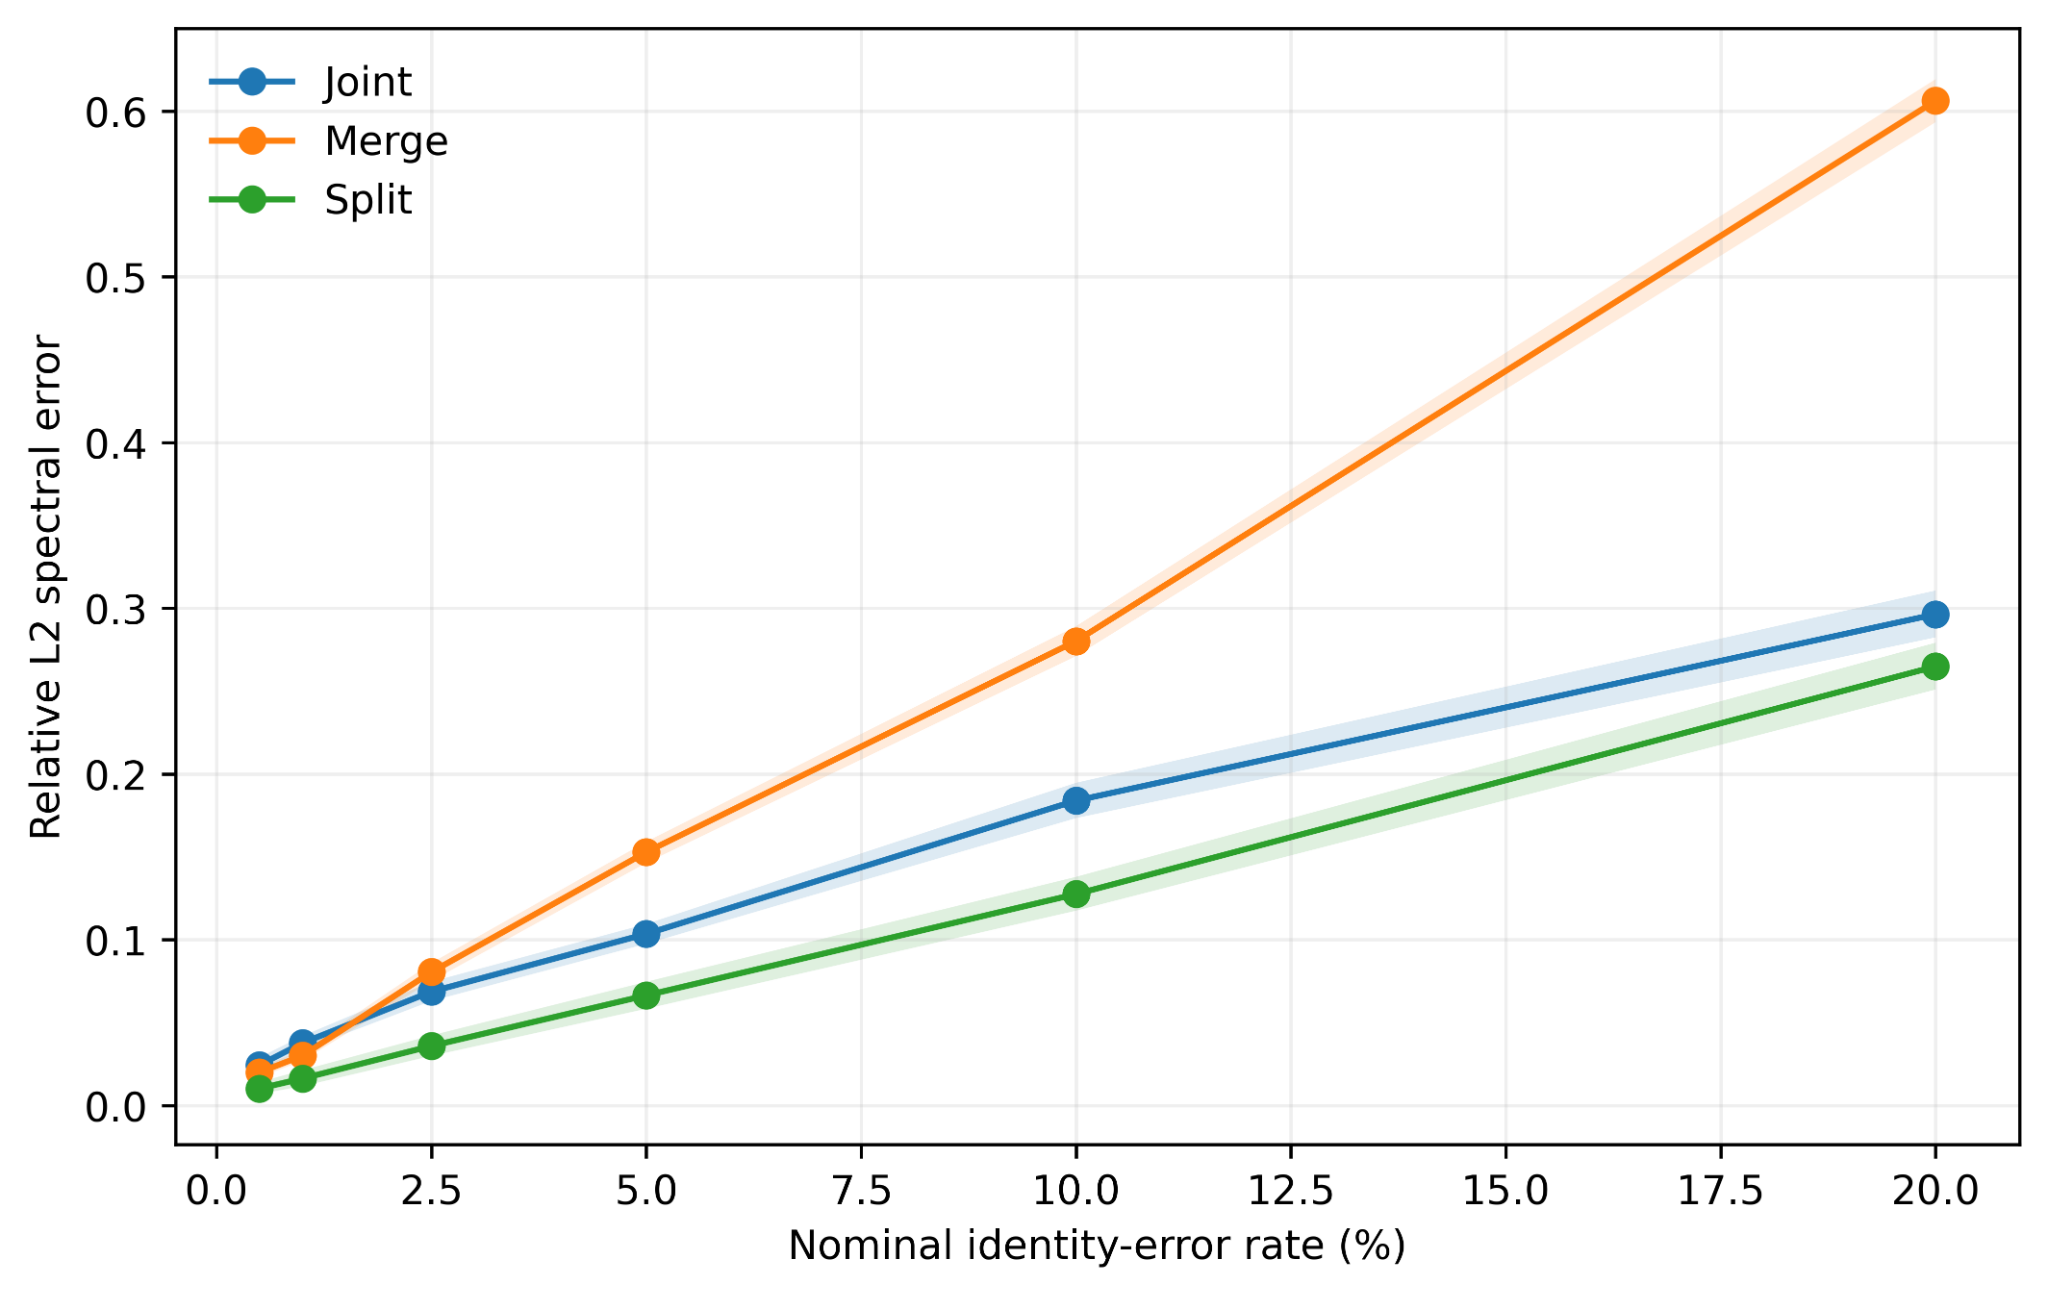

**Figure 2**

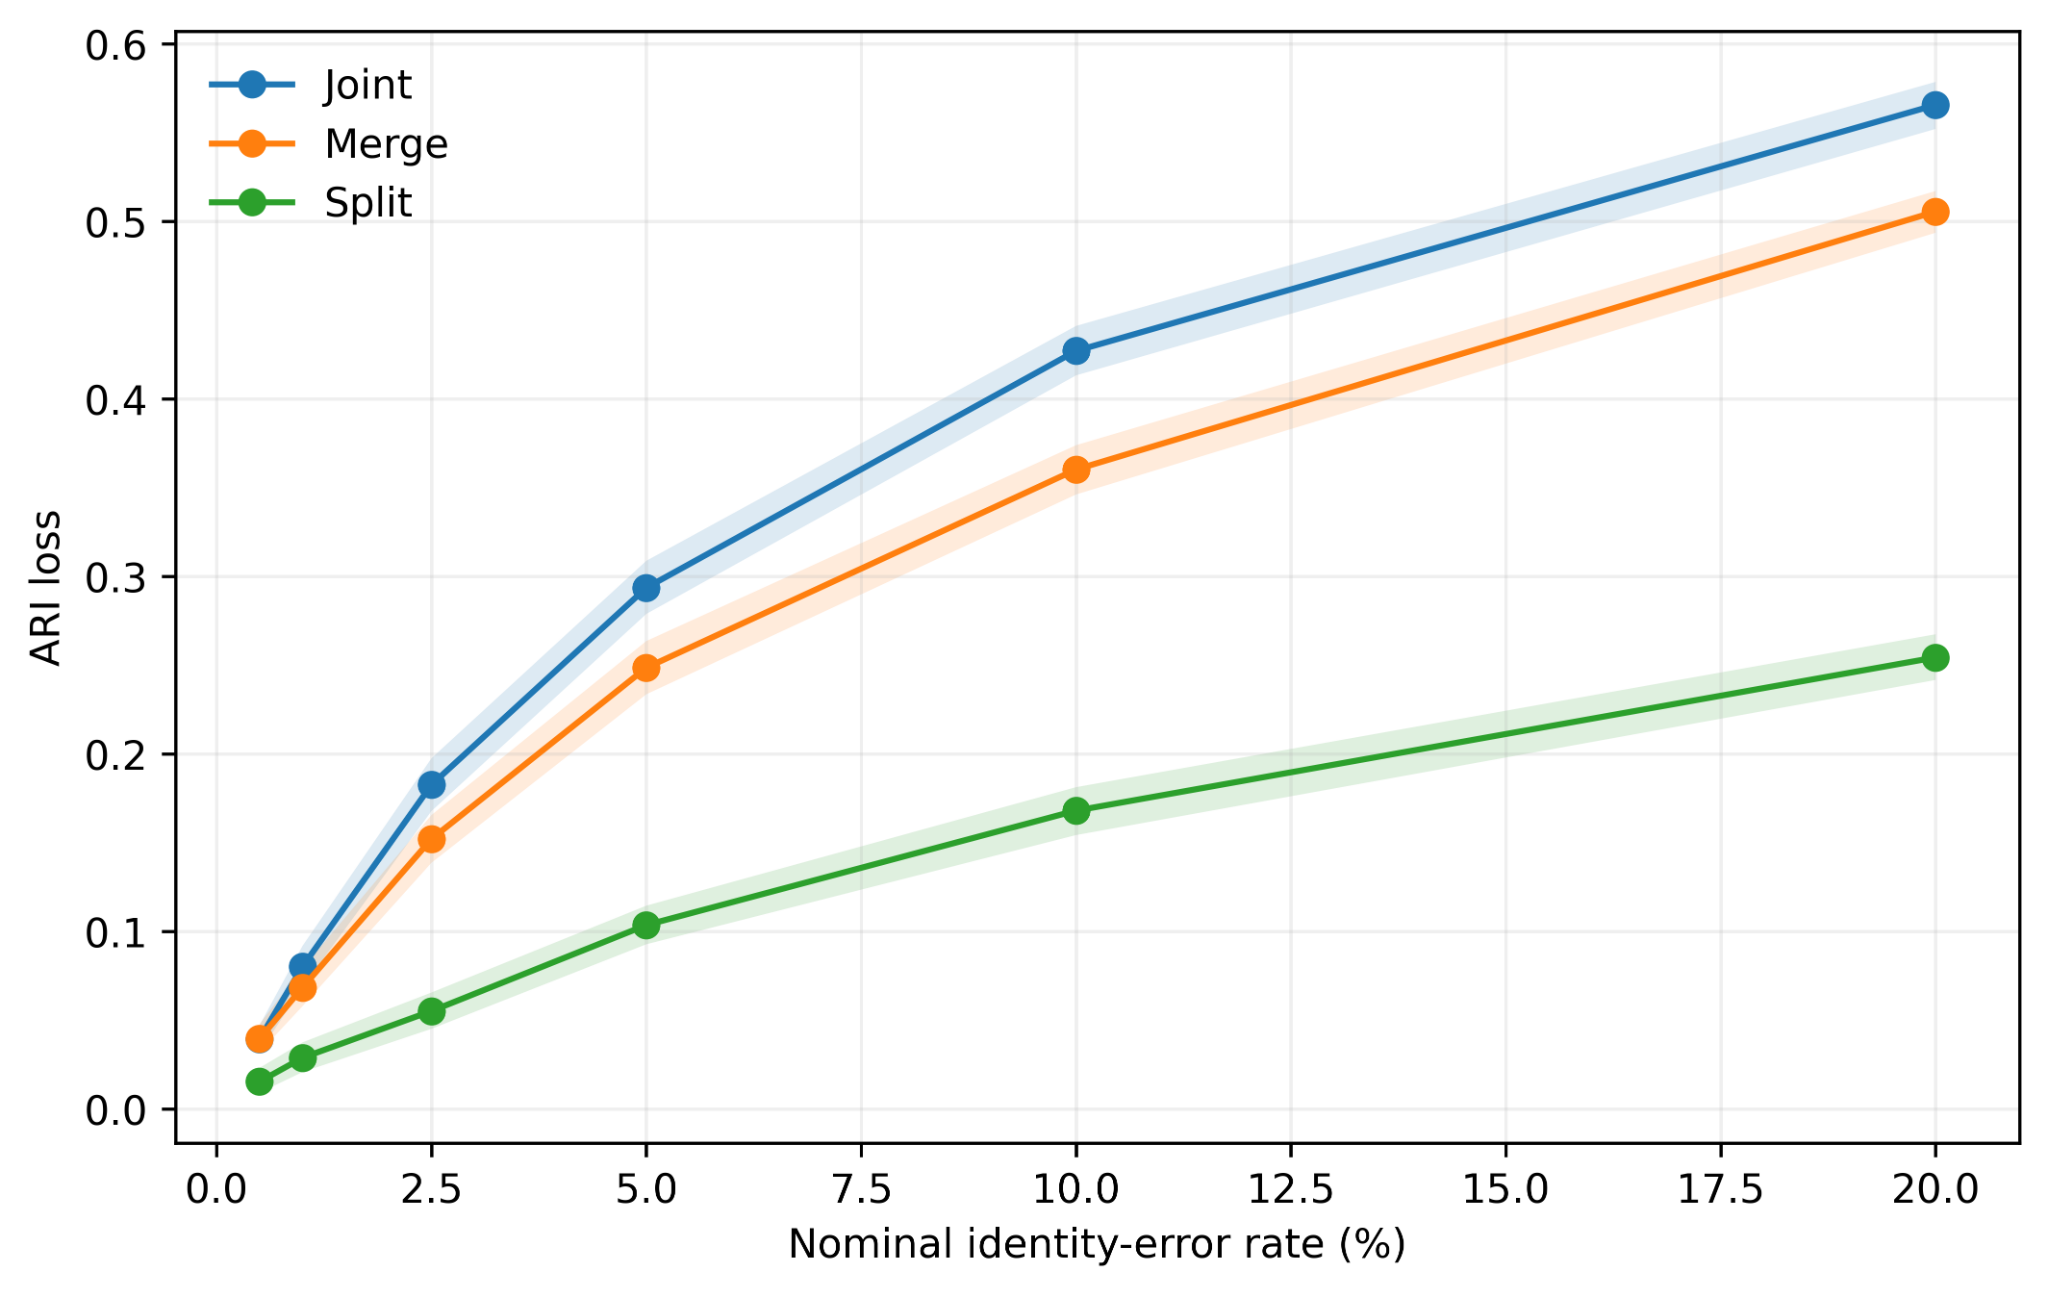

**Figure 3**

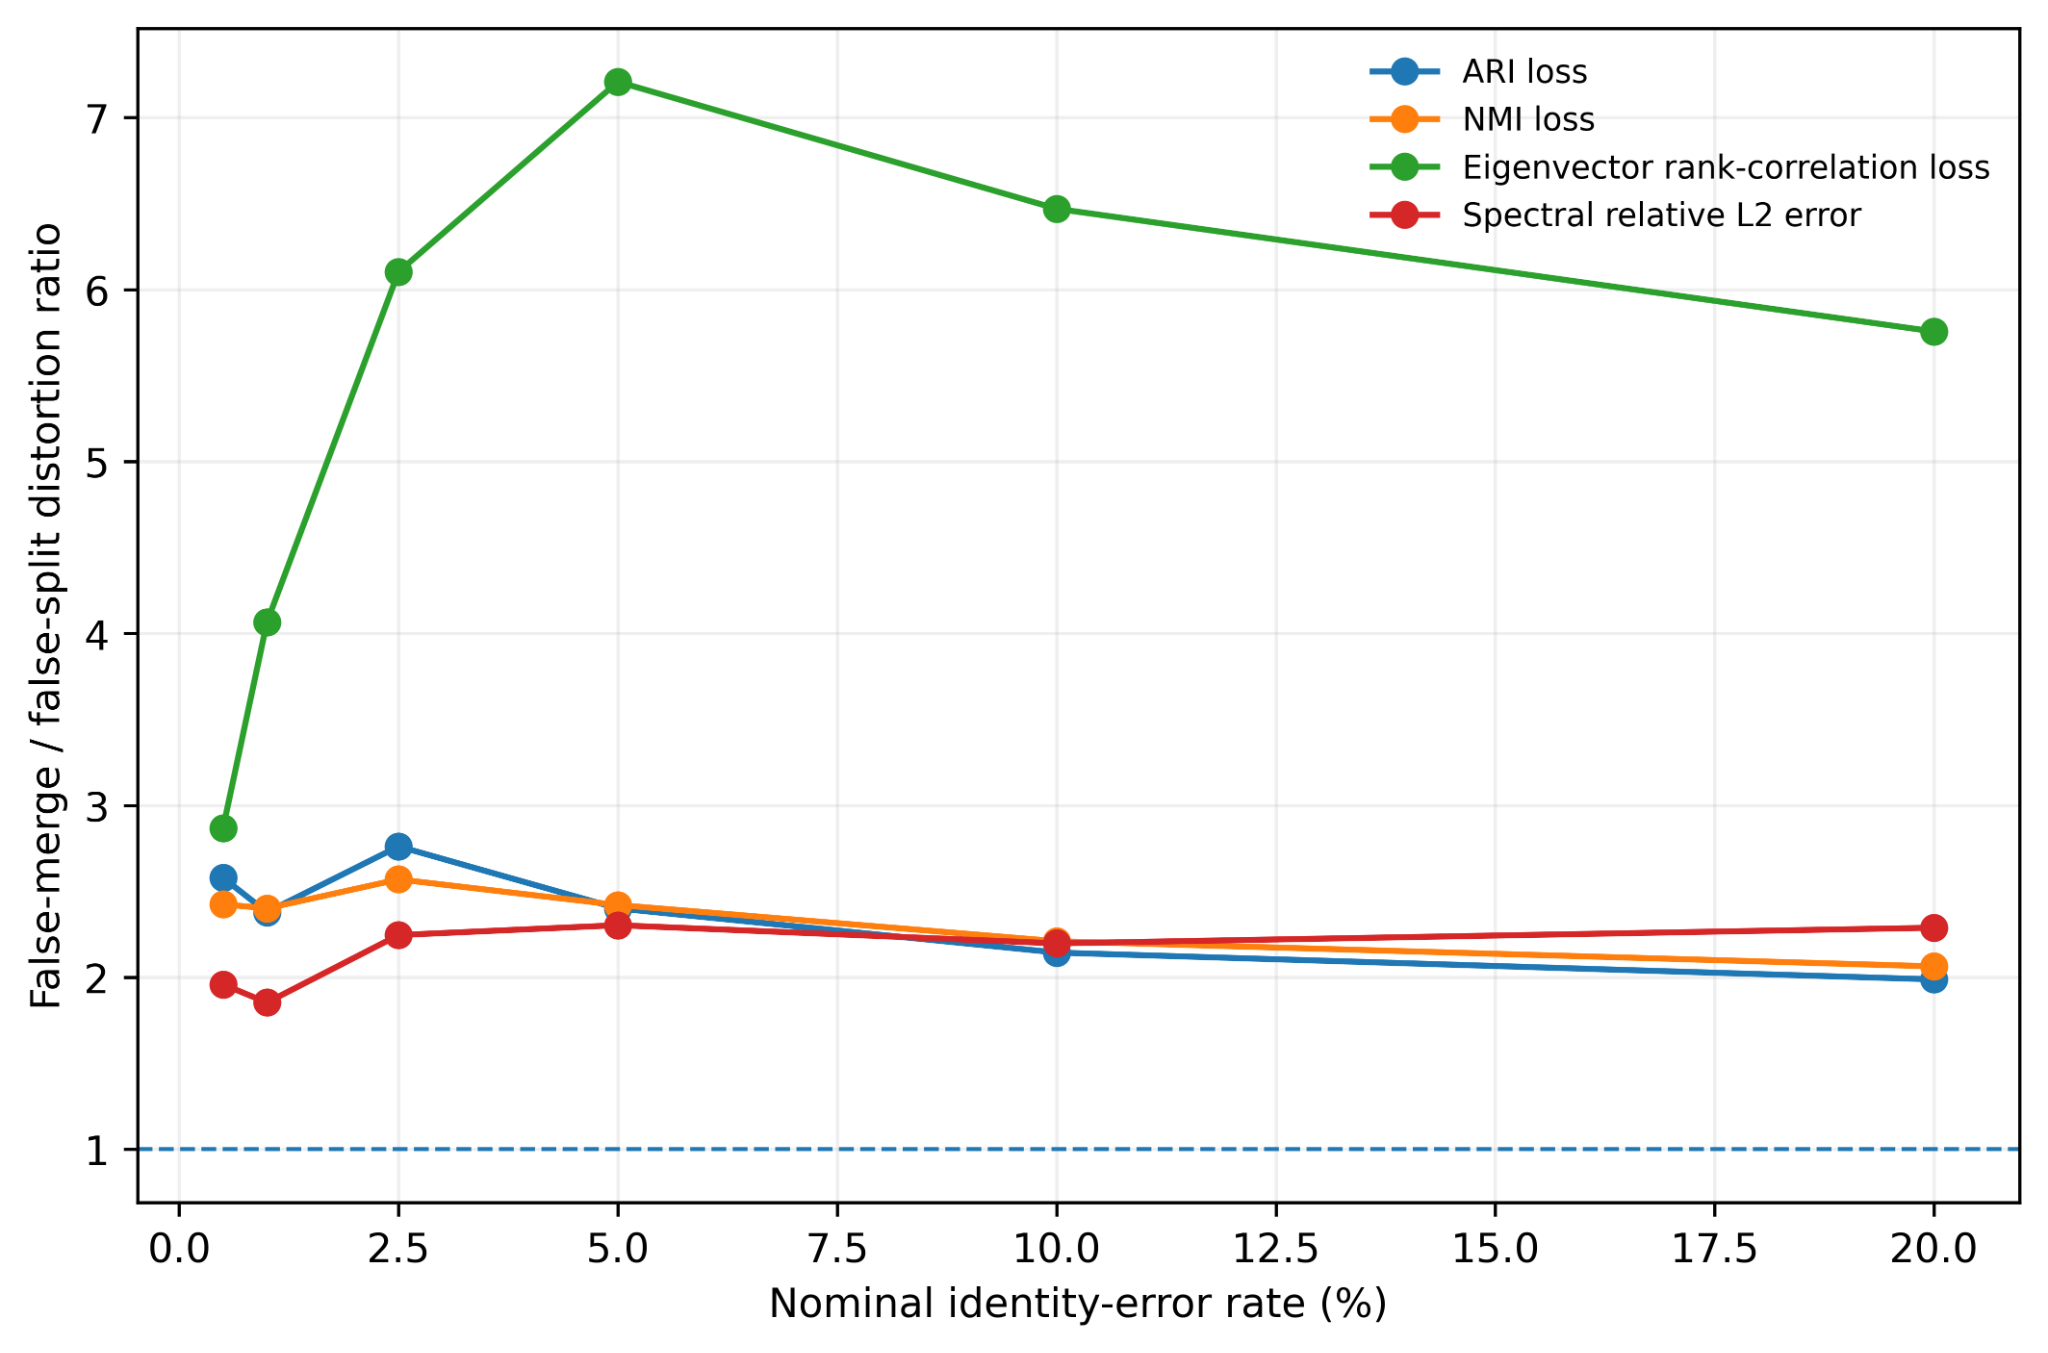

**Figure 4**

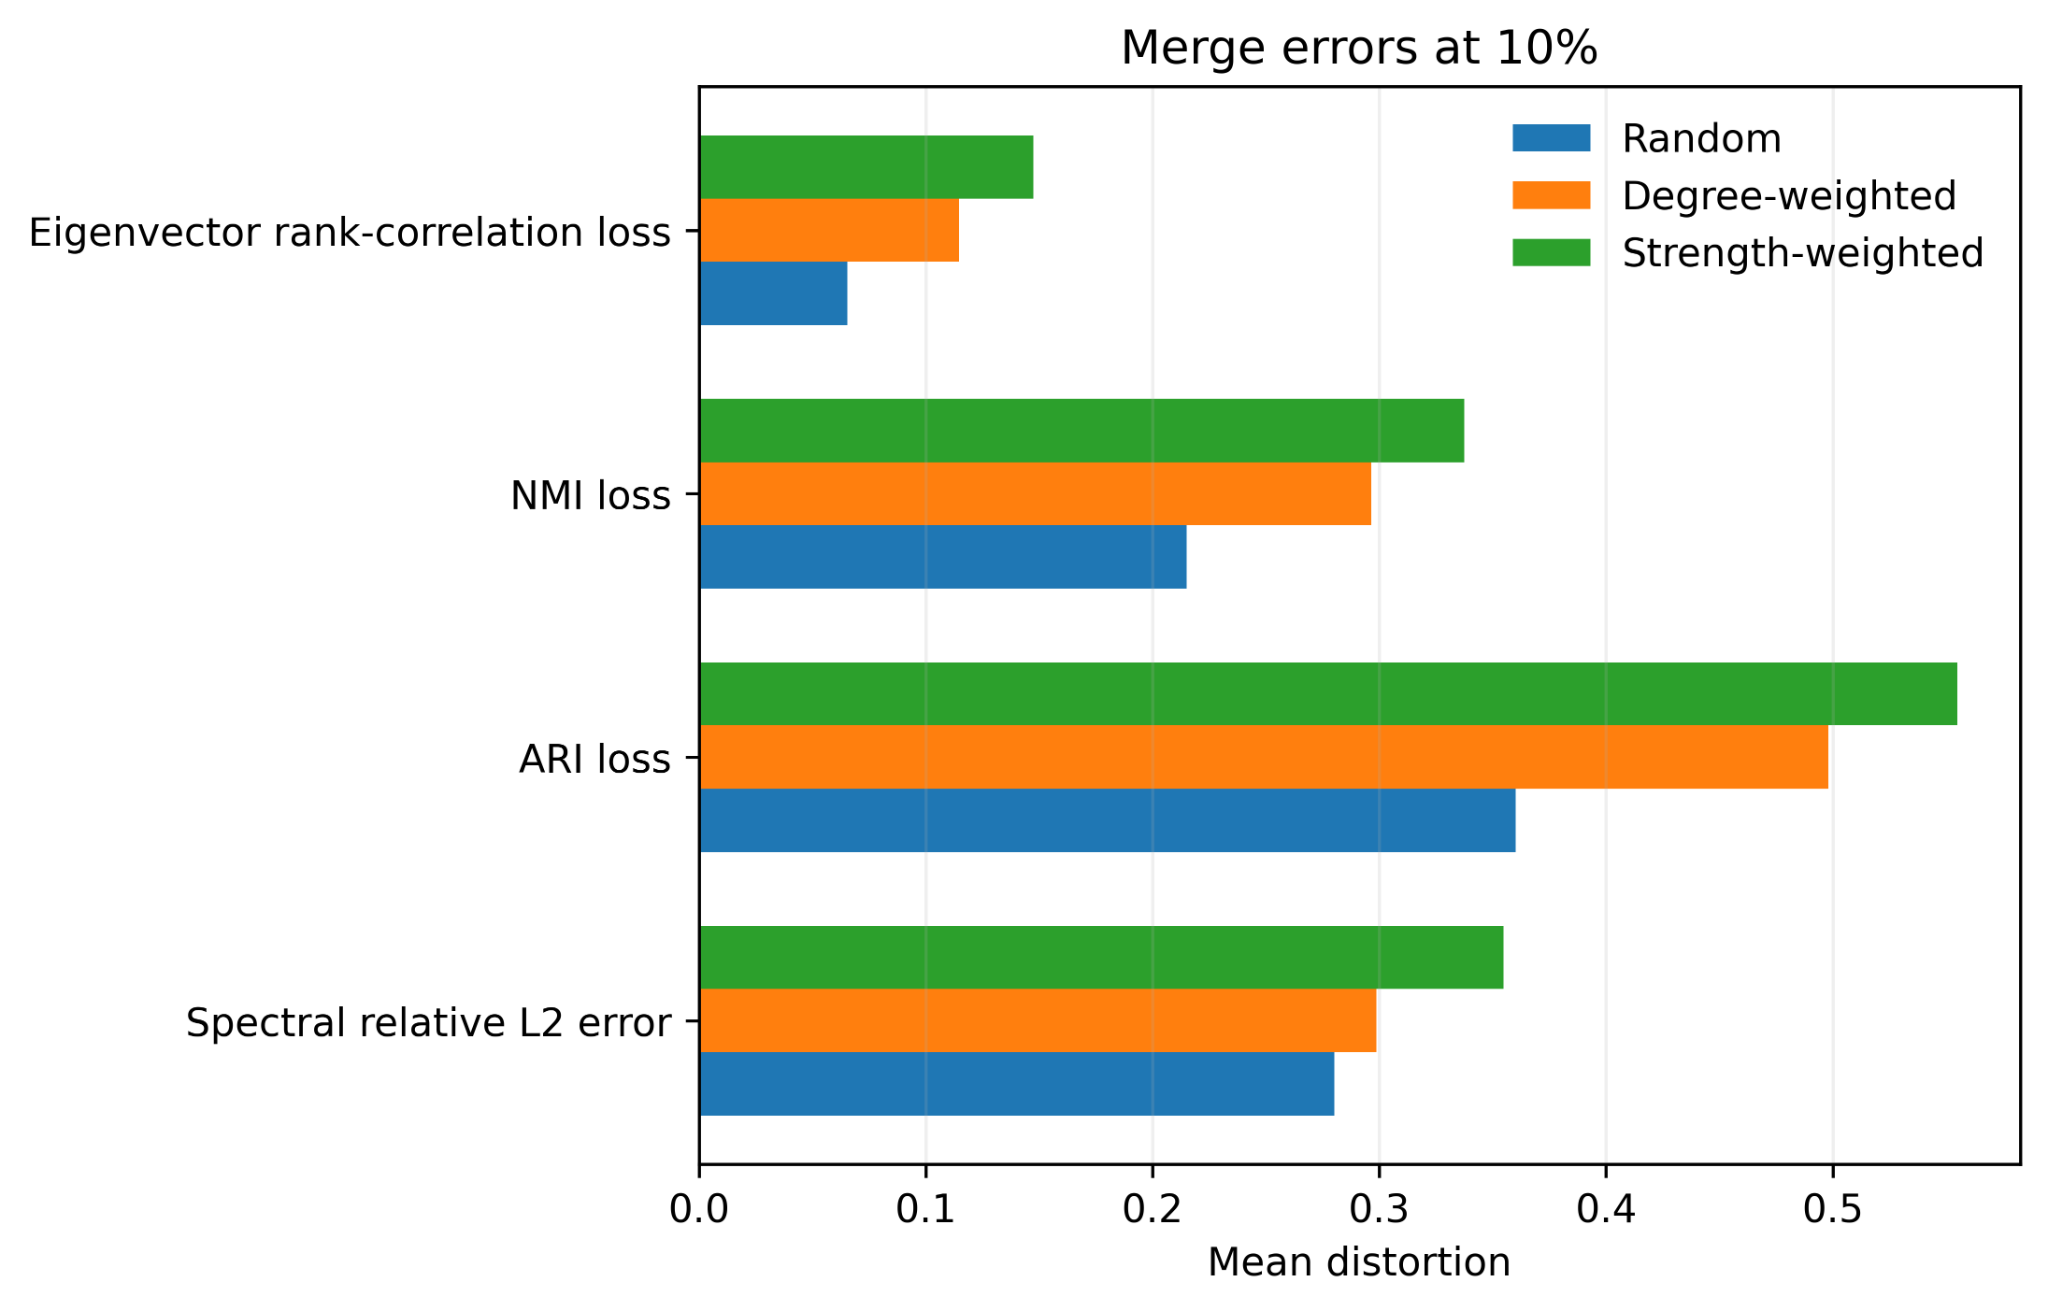

### Supplementary methods

**Supplementary methods table 1 — Supplementary Methods A — forensic metadata audit**

,Column 1,Column 2
0,Publication-table rows,"38,138"
1,Author-table rows,543
2,Unique resolved OpenAlex Author IDs,500
3,Source records missing resolved ID,8
4,Shared-ID anomalies,2 OpenAlex IDs
5,IDs with multiple normalized source names,3
6,Canonical graph nodes,404
7,Canonical graph edges,"1,600"
8,Canonical total edge weight,"5,259"
9,Canonical connected components,1


**Supplementary methods table 2 — Supplementary Methods B — candidate strata and sampling**

,Column 1,Column 2,Column 3,Column 4,Column 5,Column 6
0,High name ambiguity,High name ambiguity,"2,823","2,823",309,309
1,High uniqueness,High uniqueness,193,193,193,193
2,Weak,Weak,138,138,35,35
3,Moderate,Moderate,72,72,38,38
4,Low,Low,71,71,31,31
5,Incumbent extreme disagreement,Incumbent extreme disagreement,17,17,17,17
6,Sampling stratum,Population targets,Population targets,Sampled targets,Sampled targets,Sampling weight
7,No external candidate,6,6,6,6,1.000
8,Extreme incumbent disagreement,17,17,17,17,1.000
9,Incumbent not fetchable,10,10,10,10,1.000


...

,Column 1,Column 2,Column 3,Column 4,Column 5,Column 6,Column 7
0,1%,0.016503,0.001567,0.026445,0.008926,0.015045,0.005212
1,5%,0.069637,0.006428,0.099899,0.055986,0.055812,0.031887
2,10%,0.144892,0.009800,0.169879,0.076874,0.099542,0.047437
3,20%,0.253622,0.019997,0.245932,0.133469,0.146934,0.081788


**Table S17 — Table S17. Spectral sensitivity to eigenvalue-window size**

,Column 1,Column 2,Column 3,Column 4,Column 5,Column 6
0,Intact-edge split,1%,0.025166,0.016503,0.014416,0.013242
1,Intact-edge split,5%,0.104753,0.069637,0.054594,0.047581
2,Intact-edge split,10%,0.225128,0.144892,0.110494,0.094845
3,Intact-edge split,20%,0.382696,0.253622,0.209760,0.182927
4,Proportional split,1%,0.002429,0.001567,0.001964,0.002385
5,Proportional split,5%,0.005824,0.006428,0.006967,0.007199
6,Proportional split,10%,0.011577,0.009800,0.010529,0.013302
7,Proportional split,20%,0.023197,0.019997,0.021411,0.024561


### Supplementary figures

**Figure S1**

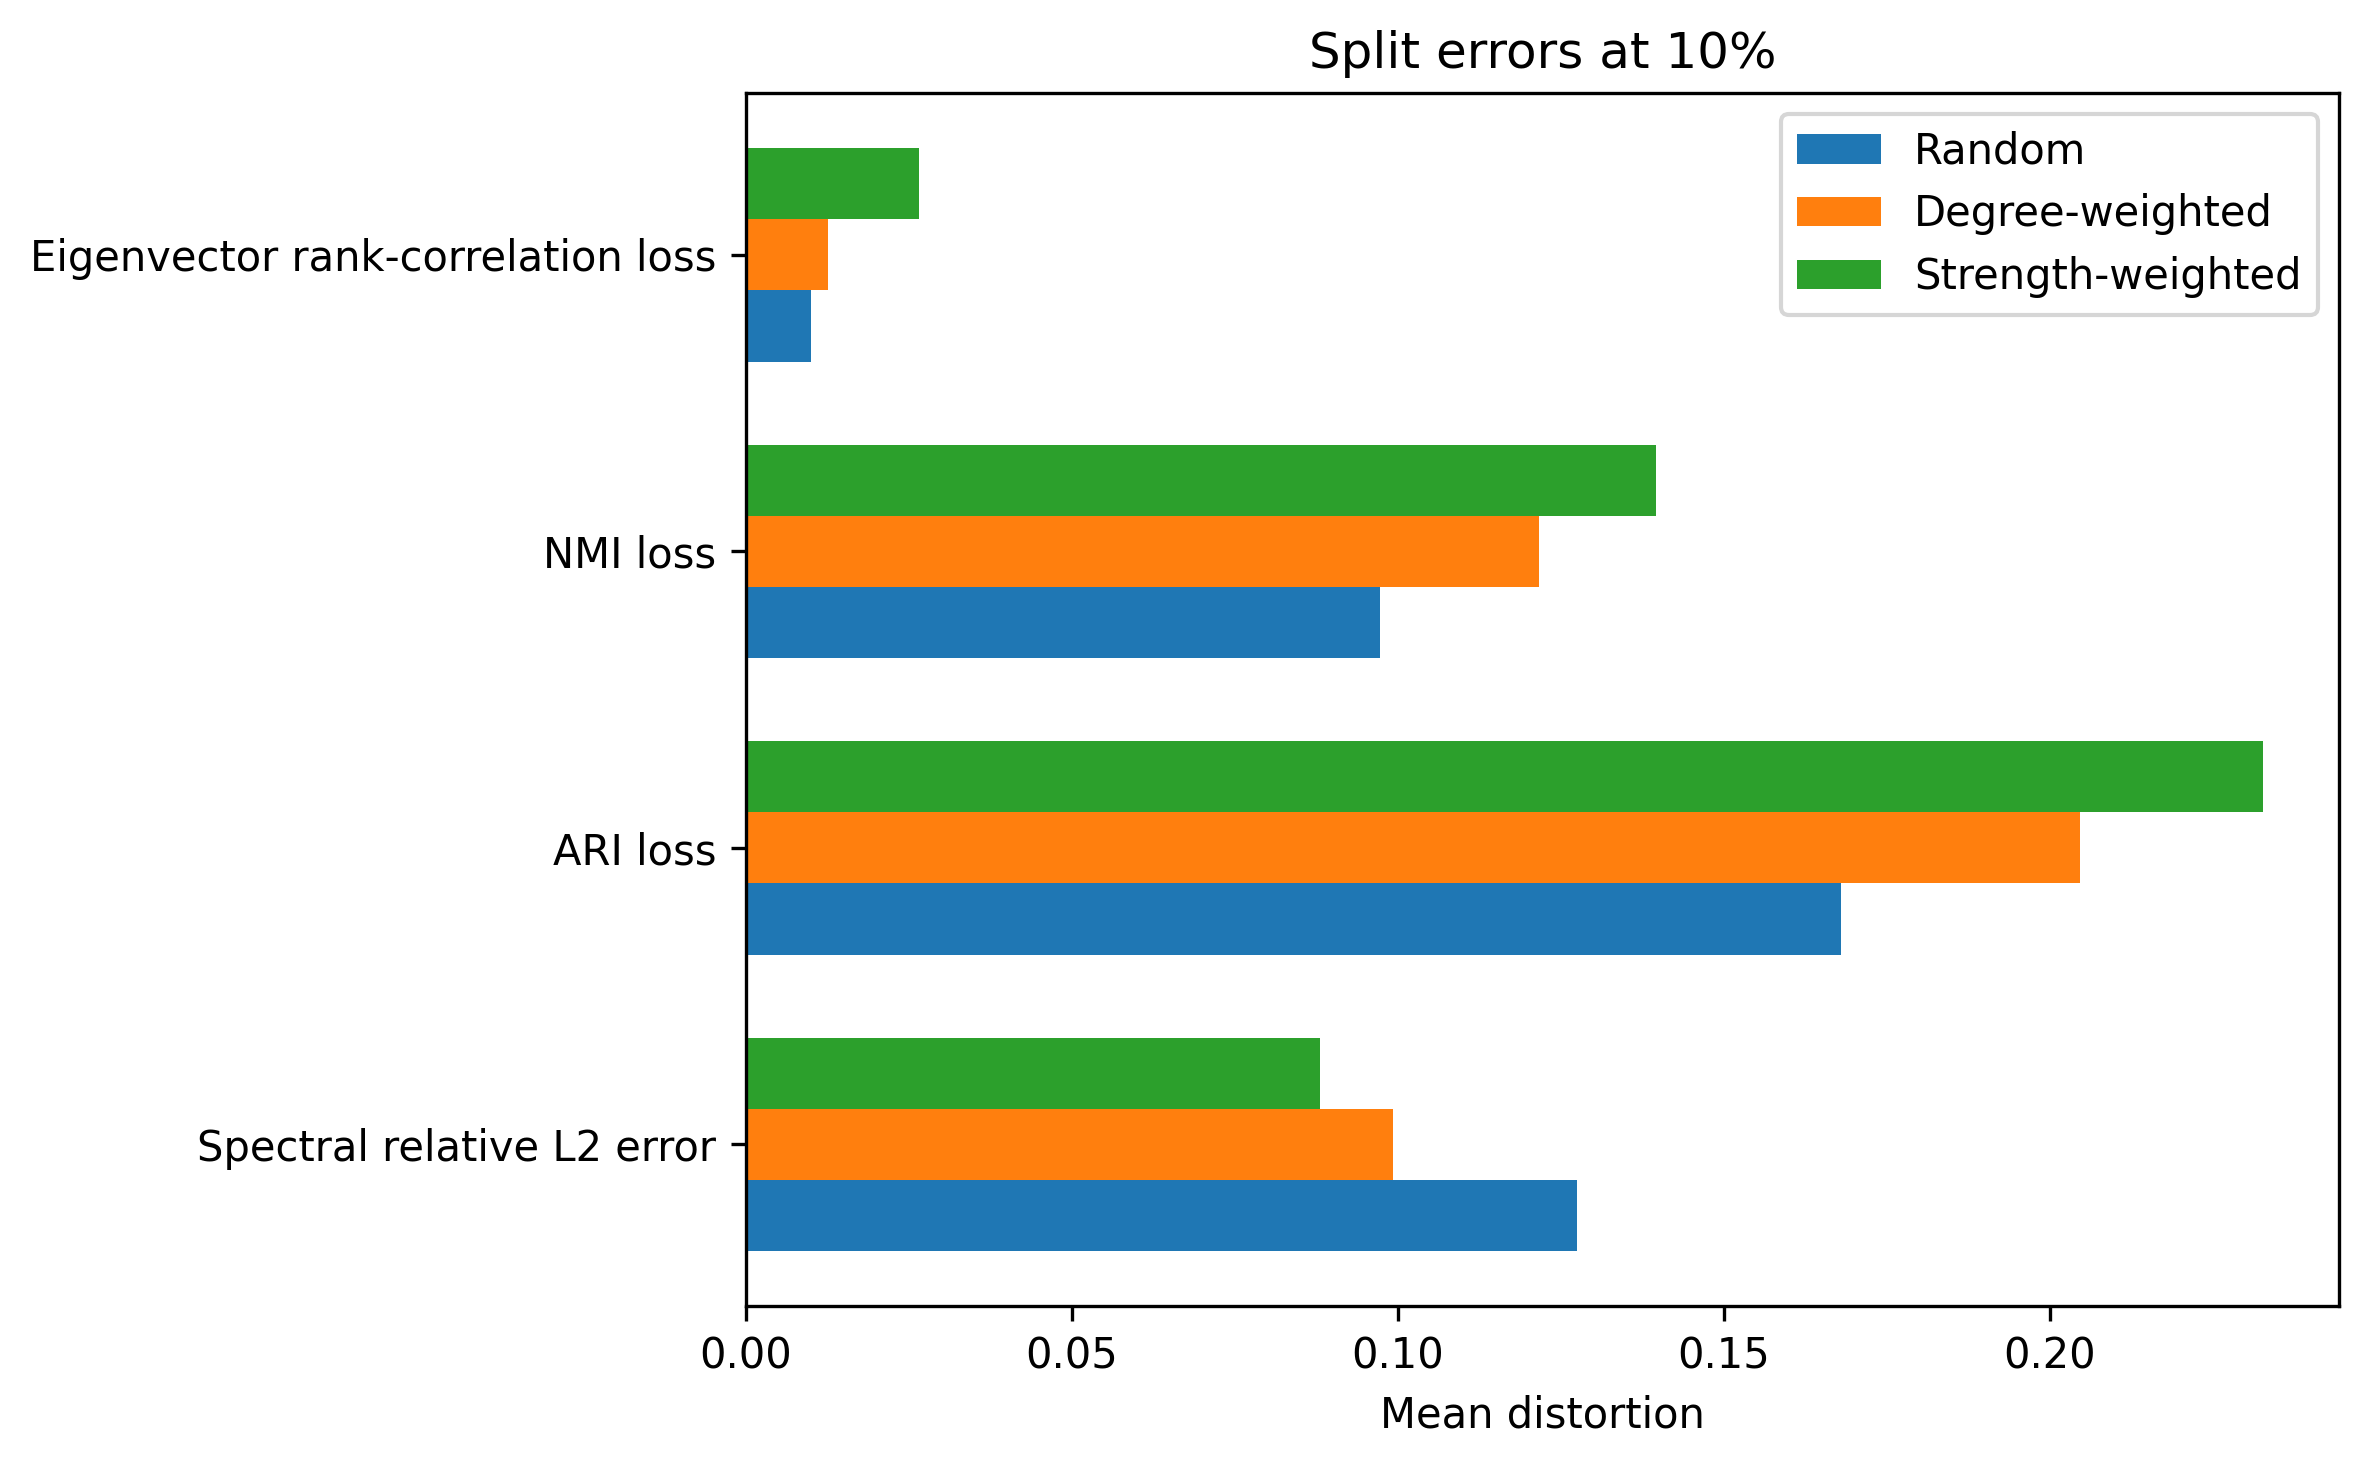

**Figure S2**

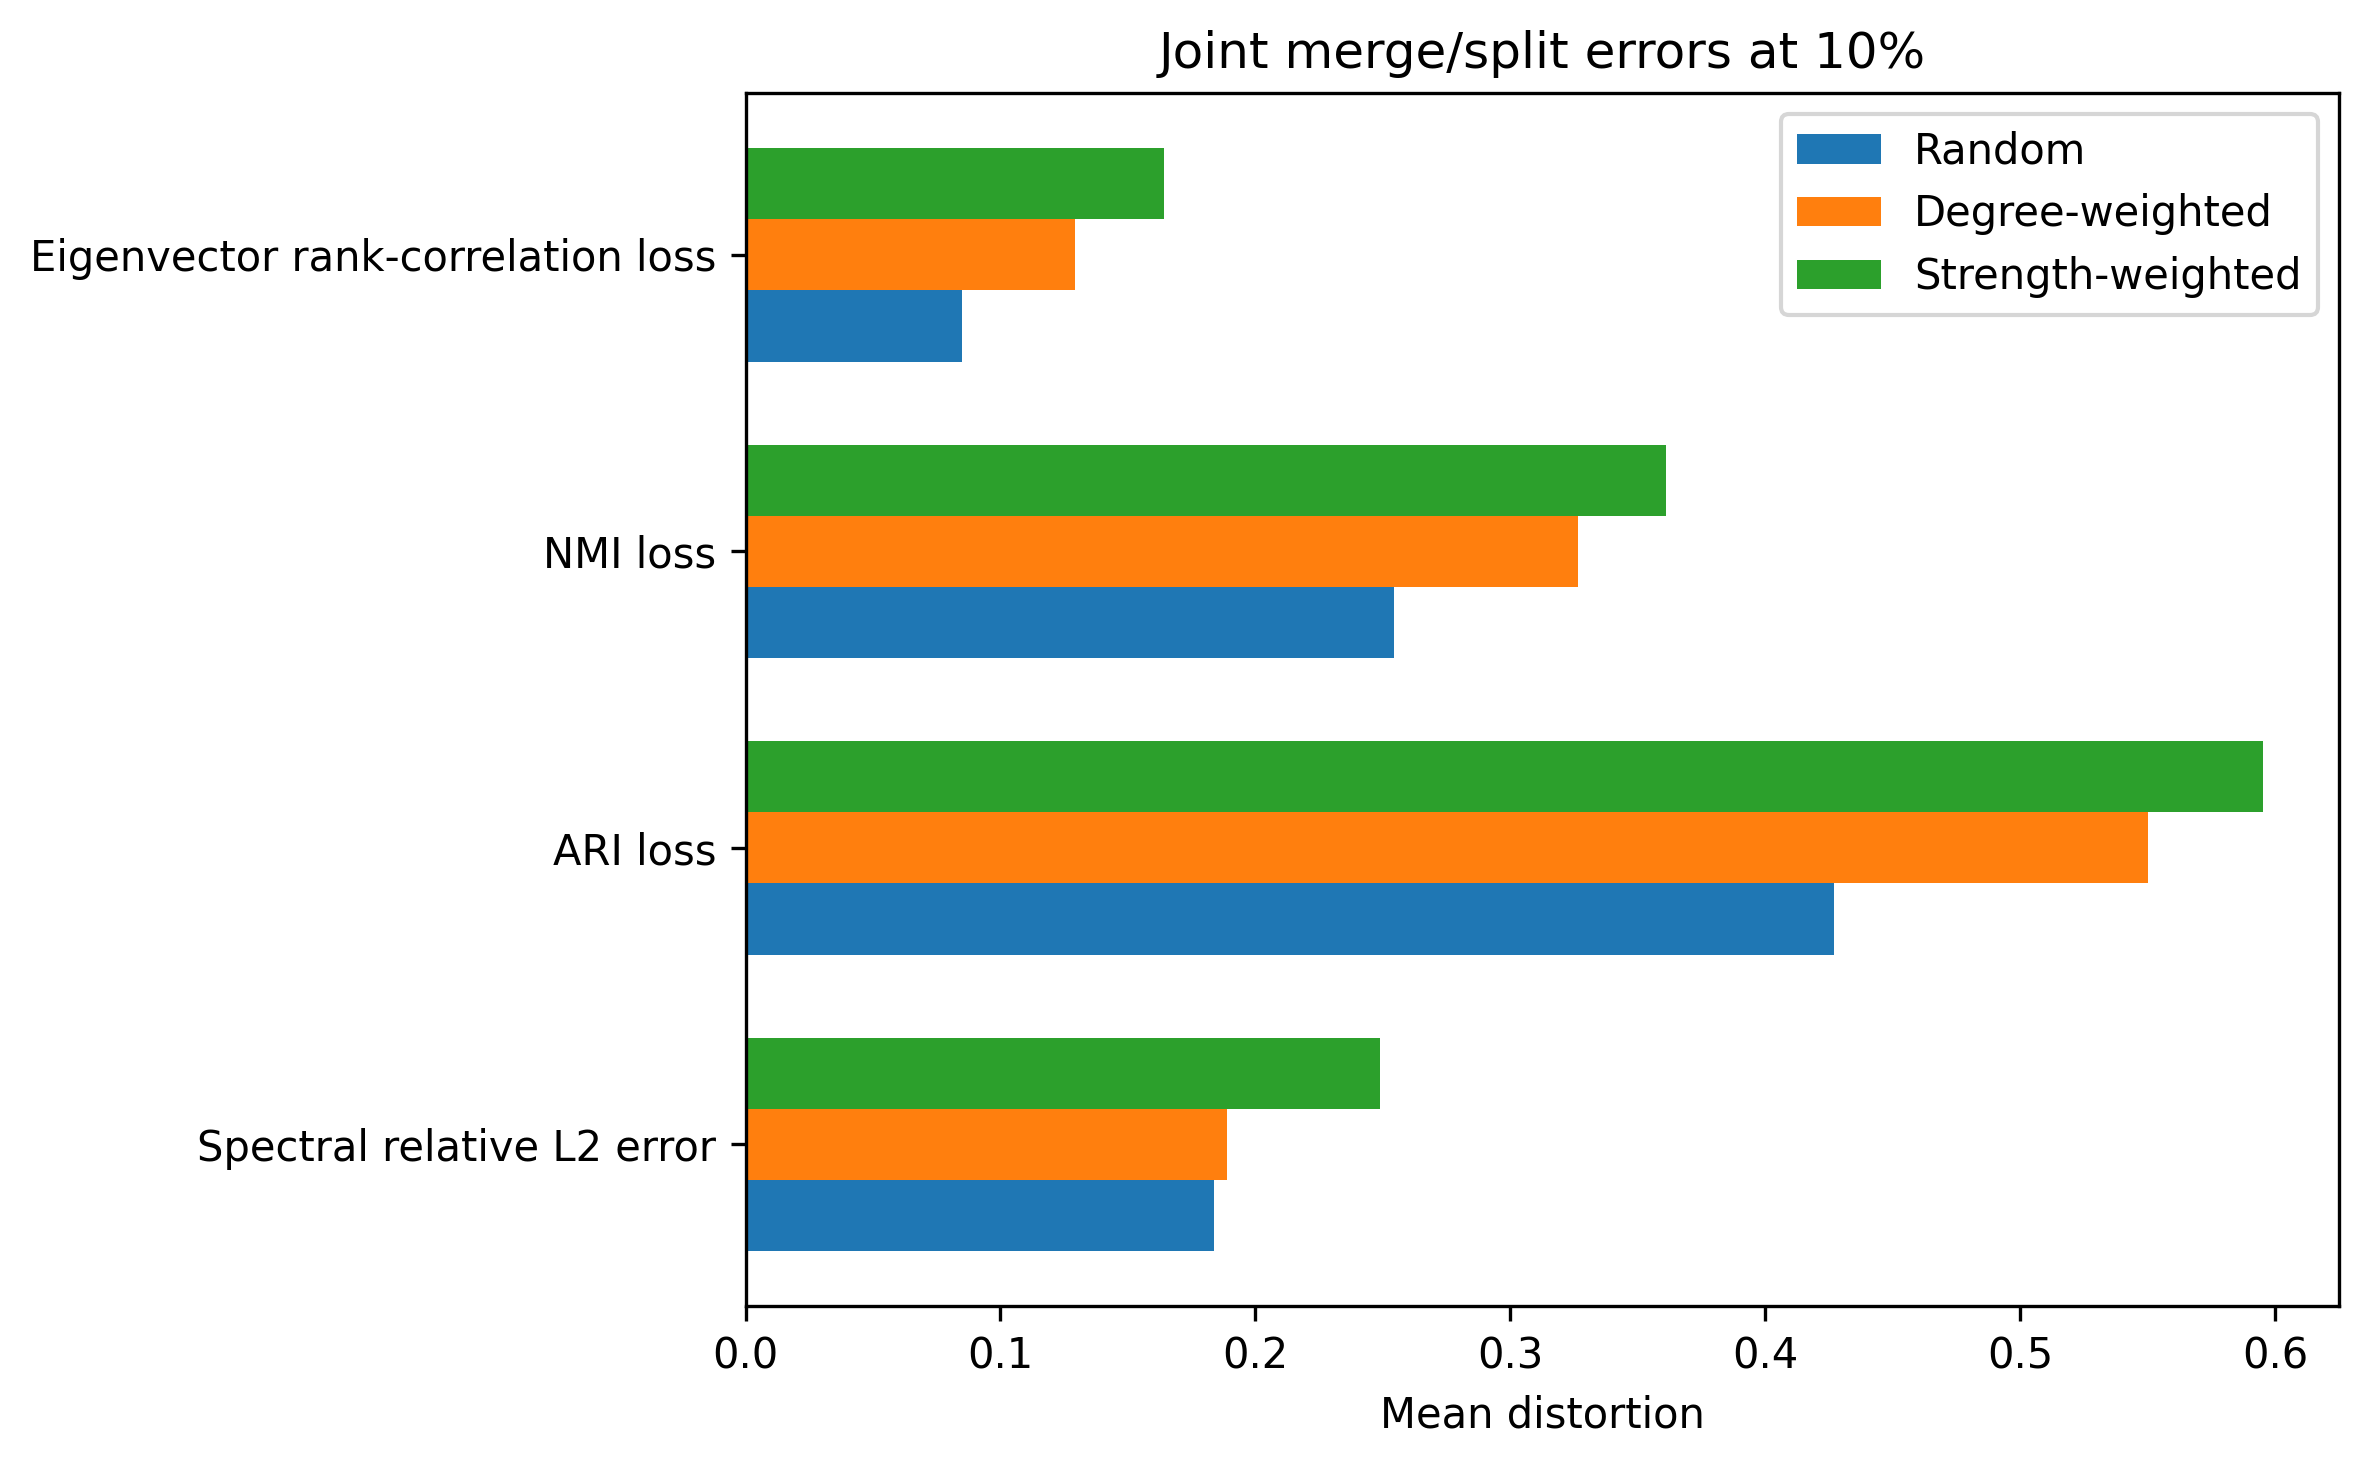

**Figure S3**

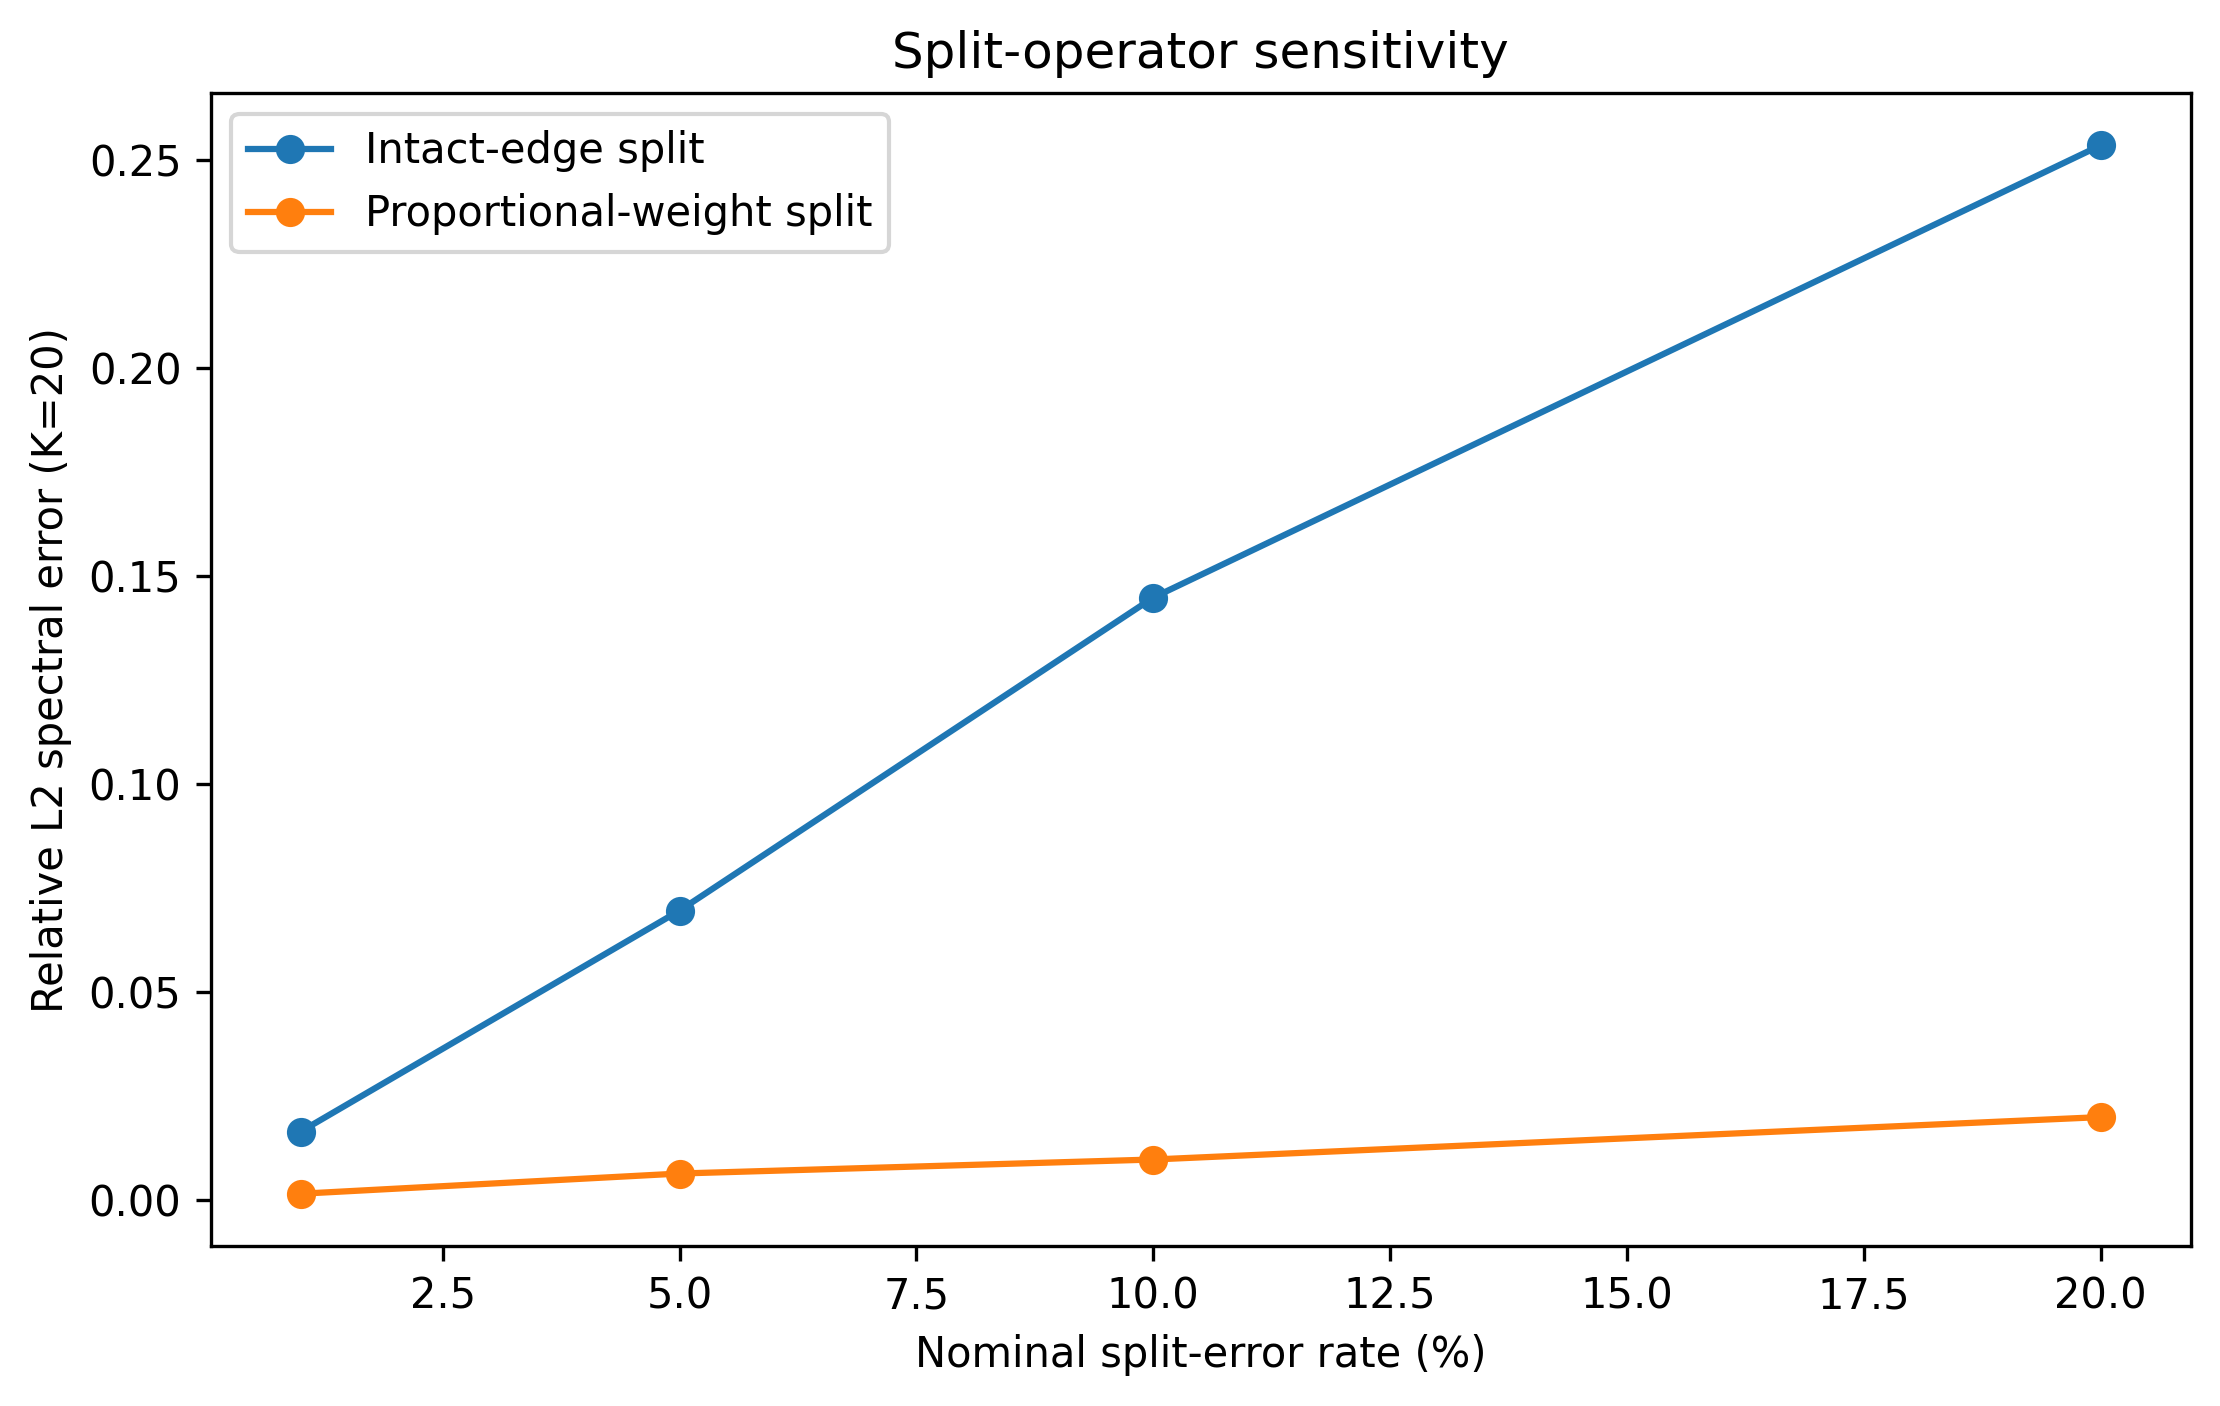

**Figure S4**

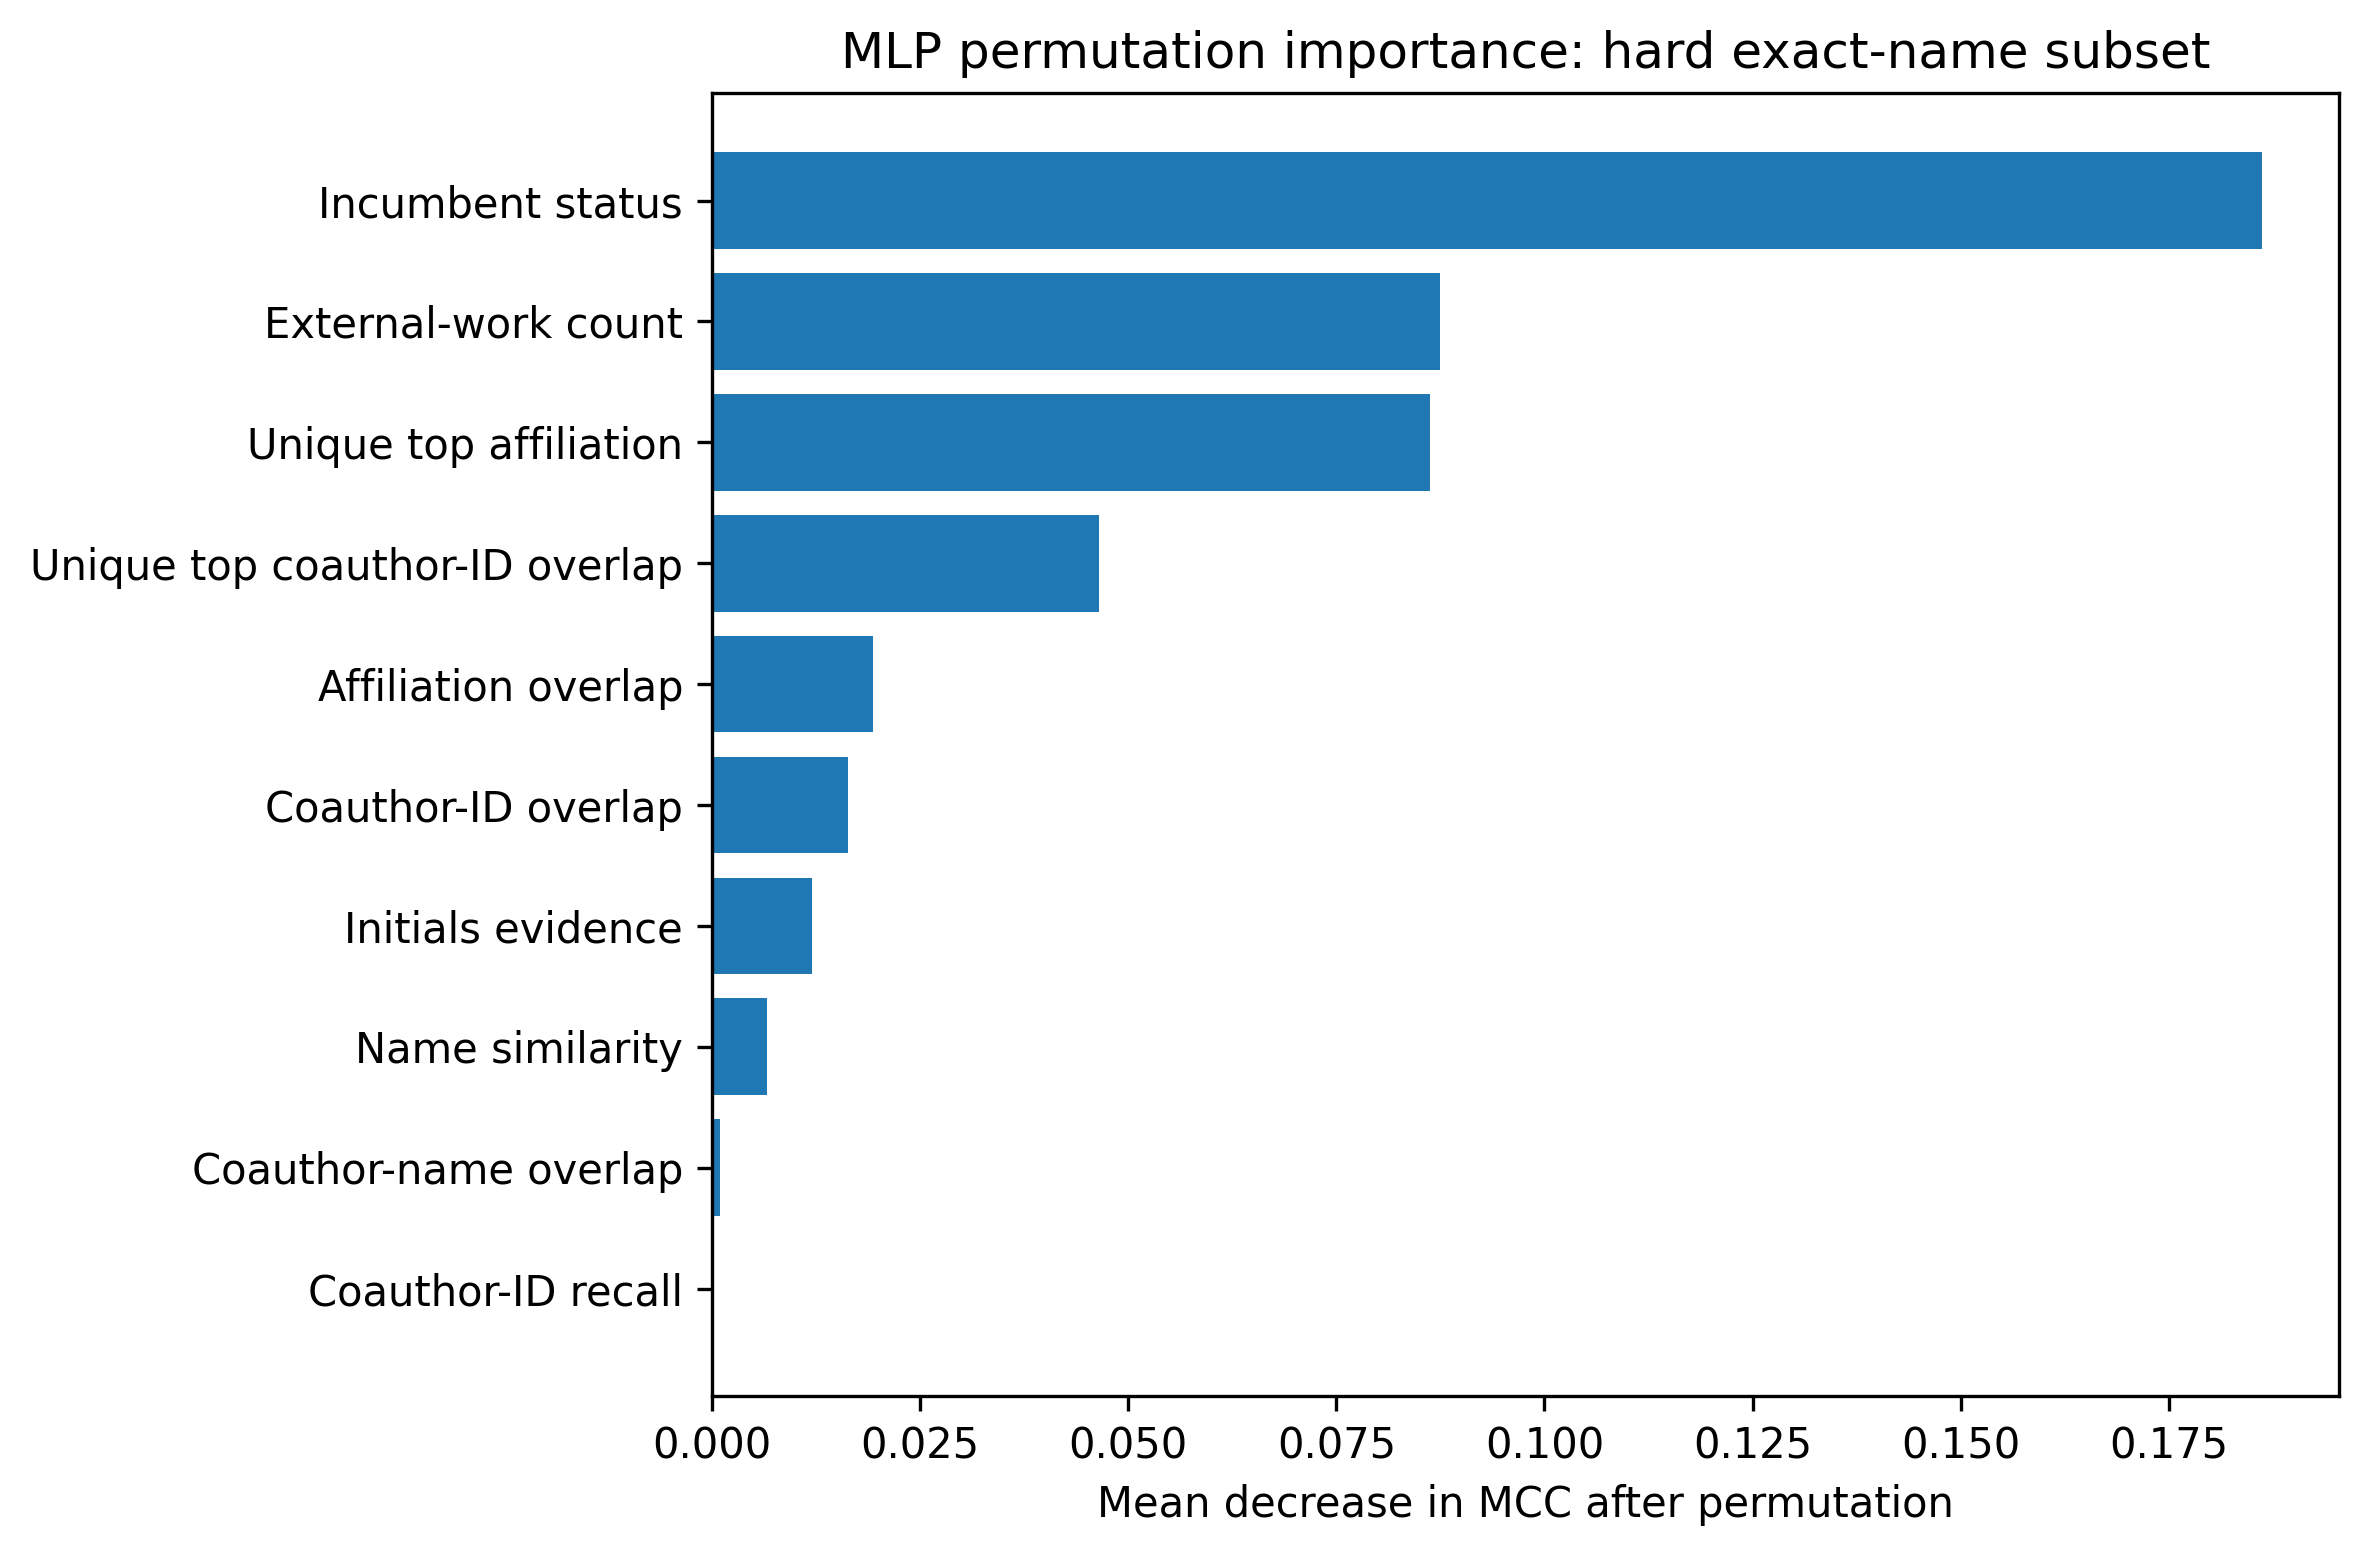

**Output folder:** `/content/drive/MyDrive/tese_doutoral/runs/ijdl_scholarly_identity_integrity/release_20261021T160218Z/07_1_publication_tables_and_figures`

**Inventory:** 25 tables; 8 figures. All values remain those supplied in the submitted version.

In [8]:
# 7.1 — IJDL publication tables and figures | CPU only | submitted-version snapshot
# Reads the exact tables/figures supplied with JOI-D-26-01089; does NOT recompute results.
# Self-contained: no path edits, external downloads, API calls, GPU, or retraining.
import base64, gzip, json, hashlib, csv, io, re
from pathlib import Path
from IPython.display import display, Markdown, Image
import pandas as pd

IJDL_SUBMISSION_SNAPSHOT_B64 = """..."""
snapshot=json.loads(gzip.decompress(base64.b64decode(IJDL_SUBMISSION_SNAPSHOT_B64)).decode('utf-8'))
# Reuse output root created in earlier notebook cells, and preserve existing release files.
if 'OUT' not in globals() or not Path(OUT).is_dir():
    # Reuse an existing release from the original, already completed notebook.
    drive_root=Path('/content/drive/MyDrive')
    if not drive_root.is_dir():
        from google.colab import drive
        drive.mount('/content/drive')
    release_root=drive_root/'tese_doutoral/runs/ijdl_scholarly_identity_integrity'
    completed=sorted([p for p in release_root.glob('release_*') if p.is_dir()]) if release_root.is_dir() else []
    if not completed:
        raise RuntimeError('No completed IJDL release was found in Drive. Run the original laboratory once first.')
    OUT=completed[-1]
    print('Existing IJDL release:',OUT)
section=Path(OUT)/'07_1_publication_tables_and_figures'
section.mkdir(parents=True, exist_ok=True)

manifest=[]
for tab in snapshot['tables']:
    name=re.sub(r'[^A-Za-z0-9]+','_',tab['id']).strip('_')
    rows=tab['rows']
    if not rows: continue
    max_cols=max(map(len,rows)); norm=[r+['']*(max_cols-len(r)) for r in rows]
    # Keep as raw cells because the submitted DOCX uses merged cells and multi-row headers.
    df=pd.DataFrame(norm)
    path=section/(name+'.csv'); df.to_csv(path,index=False,header=False,encoding='utf-8-sig')
    file_hash=hashlib.sha256(path.read_bytes()).hexdigest()
    manifest.append(dict(id=tab['id'],group=tab['group'],kind='table',path=str(path),sha256=file_hash,origin='submitted DOCX snapshot',verification='not independently numerically reconciled'))

for fig in snapshot['figures']:
    data=base64.b64decode(fig['base64'])
    assert hashlib.sha256(data).hexdigest()==fig['sha256'], f"Image source fingerprint mismatch: {fig['id']}"
    path=section/fig['filename']; path.write_bytes(data)
    assert hashlib.sha256(path.read_bytes()).hexdigest()==fig['sha256']
    manifest.append(dict(id=fig['id'],group=fig['group'],kind='figure',path=str(path),sha256=fig['sha256'],origin='submitted figure image or supplementary DOCX',verification='exact image bytes verified'))

report=pd.DataFrame(manifest)
report.to_csv(section/'publication_assets_manifest.csv',index=False)
summary={'status':'SUBMITTED_VERSION_SNAPSHOT_NOT_INDEPENDENT_REPLICATION',
 'table_count':sum(m['kind']=='table' for m in manifest),
 'figure_count':sum(m['kind']=='figure' for m in manifest),
 'sources':snapshot['sources'],
 'frozen_computation':'unchanged',
 'limitations':['Tables are exact textual cell snapshots from supplied DOCX files, not a crosscheck against primary computation exports.',
                'Merged Word cells and multi-row table headers may appear repeated in CSV; check the source before typesetting.',
                'Figures are byte-for-byte snapshots of submitted graphics, not figures freshly regenerated from experimental outputs.',
                'Do not claim that this display independently validated reported statistical results.']}
(section/'publication_assets_status.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')

# All items are shown in publication order; no reanalysis of results is performed.
display(Markdown('## 7.1 · Publication tables and figures — submitted manuscript snapshot'))
display(Markdown('**Source integrity:** tables transcribed directly from the submitted DOCX files; images verified with SHA-256. **Scientific status:** presentation snapshot, not independent numeric replication.'))
for group in ['Main article','Main figures','Supplementary methods','Supplementary tables','Supplementary figures']:
    if group.endswith('figures'):
        selected=[x for x in snapshot['figures'] if x['group']==group]
        if not selected: continue
        display(Markdown('### '+group))
        for fig in selected:
            display(Markdown('**'+fig['id']+'**'))
            display(Image(data=base64.b64decode(fig['base64']),width=820))
    else:
        selected=[x for x in snapshot['tables'] if x['group']==group]
        if not selected: continue
        display(Markdown('### '+group))
        for tab in selected:
            display(Markdown('**'+tab['id']+' — '+tab['caption']+'**'))
            display(pd.DataFrame(tab['rows'][1:],columns=[f'Column {j+1}' for j in range(max(map(len,tab['rows'])))]).fillna('') if all(len(row)==len(tab['rows'][0]) for row in tab['rows']) else pd.DataFrame(tab['rows']).fillna(''))

display(Markdown('**Output folder:** `'+str(section)+'`'))
display(Markdown(f"**Inventory:** {summary['table_count']} tables; {summary['figure_count']} figures. All values remain those supplied in the submitted version."))


# 7.2 — Publication Quality Assurance and Editorial Validation

In [9]:
# 7.2 — IJDL publication-quality assurance | CPU only
# Paste as ONE code cell immediately after 7.1. No reruns of models or simulations.
# Reads the in-memory frozen submission snapshot produced by 7.1 and verifies its exported assets.
# Writes NEW files under 07_2_publication_quality_assurance; never overwrites 7.1.
import json, hashlib, re, csv
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown

if 'snapshot' not in globals() or not isinstance(snapshot, dict) or 'tables' not in snapshot:
    raise RuntimeError('Run cell 7.1 first in this Colab session. Cell 7.2 requires its `snapshot` object.')
if 'section' not in globals() or not Path(section).is_dir():
    raise RuntimeError('Cell 7.1 output folder (`section`) was not found; run 7.1 first.')

source_dir = Path(section).resolve()
qa_dir = source_dir.parent / '07_2_publication_quality_assurance'
qa_dir.mkdir(parents=True, exist_ok=True)
clean_dir = qa_dir / 'publication_ready_tables'
clean_dir.mkdir(exist_ok=True)

# Preserve exact SOURCE strings. Do not coerce rounded results to float for export.
def text_cell(v):
    return '' if v is None else str(v).strip()

def snapshot_table(tab):
    rows = [[text_cell(x) for x in row] for row in tab['rows']]
    if len(rows) < 2:
        raise ValueError(f"Empty/unusable snapshot table: {tab['id']}")
    n = len(rows[0]); header = rows[0]
    if any(len(r) != n for r in rows):
        raise ValueError(f"Ragged table, requires source review: {tab['id']}")
    if len(set(header)) != len(header):
        raise ValueError(f"Duplicate headings, requires explicit parsing: {tab['id']}")
    return pd.DataFrame(rows[1:], columns=header)

issues=[]; checked=[]; cleaned={}
def issue(level, item, message):
    issues.append({'level':level,'item':item,'message':message})

def emit_table(identifier, df, origin, note=''):
    safe = re.sub(r'[^A-Za-z0-9]+','_',identifier).strip('_')
    out = clean_dir / f'{safe}.csv'
    df.to_csv(out,index=False,encoding='utf-8-sig')
    cleaned[identifier]=df
    checked.append({'item':identifier,'kind':'table','origin':origin,'output':str(out),
                    'rows':len(df),'columns':len(df.columns),
                    'sha256':hashlib.sha256(out.read_bytes()).hexdigest(),'note':note})

for tab in snapshot['tables']:
    tid=tab['id']
    rows=[[text_cell(x) for x in r] for r in tab['rows']]
    if tid == 'Supplementary methods table 2':
        # This DOCX table is two vertically stacked blocks with repeated merged-cell text.
        # The first block has 3 logical columns; the second block has 4.
        header_index = next((i for i,r in enumerate(rows) if any('Sampling stratum'==x for x in r)), None)
        if header_index is None:
            issue('ERROR',tid,'Could not locate embedded Sampling stratum header')
            continue
        first=rows[1:header_index]
        second=rows[header_index+1:]
        # Verify duplicate source cells agree before de-duplicating them.
        def repeated_pair(r, a, b):
            return len(r)>max(a,b) and r[a]==r[b]
        if not all(repeated_pair(r,0,1) and repeated_pair(r,2,3) and repeated_pair(r,4,5) for r in first):
            issue('ERROR',tid,'The candidate-stratum block is not a verified repeated-pair layout')
            continue
        if not all(repeated_pair(r,1,2) and repeated_pair(r,3,4) for r in second):
            issue('ERROR',tid,'The sampling block is not a verified repeated-pair layout')
            continue
        a=pd.DataFrame([[r[0],r[2],r[4]] for r in first],columns=['Final candidate stratum','Candidate pairs','Targets'])
        b=pd.DataFrame([[r[0],r[1],r[3],r[5]] for r in second],columns=['Sampling stratum','Population targets','Sampled targets','Sampling weight'])
        emit_table('Supplementary_Methods_B_Candidate_Strata',a,tid,'Separated duplicate merged cells')
        emit_table('Supplementary_Methods_B_Target_Sampling',b,tid,'Separated repeated sampling header')
        continue
    if tid == 'Table S14':
        # Repeated Ratio belongs to two different nominal-rate blocks.
        header=['Metric','0.5% merge','0.5% split','0.5% ratio','10% merge','10% split','10% ratio']
        if len(rows[0])!=7: issue('ERROR',tid,'Unexpected S14 schema'); continue
        emit_table(tid,pd.DataFrame(rows[1:],columns=header),tid,'Disambiguated repeated ratio headings')
        continue
    if tid=='Supplementary methods table 3':
        # The source contains two independent logical blocks separated by a header row.
        split_idx=next((i for i,r in enumerate(rows) if len(r)>=2 and r[0]=='Reference outcome' and r[1]=='Candidate pairs'),None)
        if split_idx is None:
            issue('ERROR',tid,'Reference-outcome subsection heading missing')
            continue
        a=pd.DataFrame(rows[1:split_idx],columns=['Target-work audit class','Rows'])
        b=pd.DataFrame(rows[split_idx+1:],columns=['Reference outcome','Candidate pairs'])
        emit_table('Supplementary_Methods_C_Work_Audit',a,tid,'Split logical source blocks')
        emit_table('Supplementary_Methods_C_Reference_Outcome',b,tid,'Split logical source blocks')
        continue
    try:
        df=snapshot_table(tab)
        # PDF / Pandas display truncation does not imply lost bytes. Check stored snapshot strings.
        truncated=[(i,c) for i,row in df.iterrows() for c,v in row.items() if ('...' in v or '…' in v) and v not in ('—','–')]
        if truncated:
            issue('WARNING',tid,f'Possible literal ellipsis in {len(truncated)} stored cells; inspect source')
        emit_table(tid,df,'submitted DOCX snapshot','No statistical recomputation')
    except ValueError as exc:
        issue('ERROR',tid,str(exc))

# Verify image files from 7.1 against exact bytes stored in the submission snapshot.
image_ok=0
for fig in snapshot['figures']:
    p=source_dir/fig['filename']
    if not p.is_file():
        issue('ERROR',fig['id'],f'Missing figure from 7.1: {p.name}')
        continue
    observed=hashlib.sha256(p.read_bytes()).hexdigest()
    if observed != fig['sha256']:
        issue('ERROR',fig['id'],'Image SHA-256 mismatch')
    else:
        image_ok+=1
        checked.append({'item':fig['id'],'kind':'figure','origin':'7.1 image export','output':str(p),
                        'rows':None,'columns':None,'sha256':observed,'note':'Byte identity verified'})

# Textual crosschecks: compare corresponding displayed quantities without floating-point rounding.
def check_equal(a,row_a,col_a,b,row_b,col_b,label):
    if a not in cleaned or b not in cleaned:
        issue('ERROR',label,'One or both tables absent'); return
    x=cleaned[a]; y=cleaned[b]
    try:
        va=x.loc[x.iloc[:,0]==row_a,col_a].iloc[0]
        vb=y.loc[y.iloc[:,0]==row_b,col_b].iloc[0]
        if va!=vb: issue('ERROR',label,f'Mismatch: {a}={va} vs {b}={vb}')
    except Exception as ex:
        issue('ERROR',label,f'Crosscheck unavailable: {ex}')

for metric in ['Precision','Recall','F1','Balanced accuracy','MCC','FPR']:
    check_equal('Table 3',metric,'OpenAlex incumbent','Table S3',metric,'B7 incumbent',f'Table 3 / S3 B7 {metric}')
    check_equal('Table 3',metric,'Multi-evidence resolver','Table S3',metric,'P6D deterministic',f'Table 3 / S3 P6D {metric}')
    check_equal('Table 3',metric,'Learned MLP','Table S3',metric,'Learned MLP',f'Table 3 / S3 MLP {metric}')

# Compare the per-method held-out baseline rows across tables 2 and S1.
if 'Table 2' in cleaned and 'Table S1' in cleaned:
    d1,d2=cleaned['Table 2'],cleaned['Table S1']
    # Compare by unambiguous baseline ID (B0...B7); labels may use abbreviations.
    index1={re.match(r'^B[0-7]\b',x).group():x for x in d1['Method'] if re.match(r'^B[0-7]\b',x)}
    index2={re.match(r'^B[0-7]\b',x).group():x for x in d2['Method'] if re.match(r'^B[0-7]\b',x)}
    for baseline in sorted(set(index1)&set(index2)):
        for metric in ['Precision','Recall','F1','Balanced accuracy','MCC','FPR']:
            v1=d1.loc[d1['Method']==index1[baseline],metric].iloc[0]
            v2=d2.loc[d2['Method']==index2[baseline],metric].iloc[0]
            if v1!=v2: issue('ERROR',f'Table 2 / S1 {baseline} {metric}',f'{v1} != {v2}')
    if len(index1)!=8 or len(index2)!=8: issue('WARNING','Table 2 / S1','Expected eight baseline IDs in both tables')

# Basic internal consistency; these are arithmetic checks only, not rerunning research.
try:
    t1=dict(zip(cleaned['Table 1']['Quantity'],cleaned['Table 1']['Value']))
    if int(t1['Reference-positive pairs'])+int(t1['Reference-negative pairs'])!=int(t1['Benchmarkable pairs'].split(' ')[0]):
        issue('ERROR','Table 1','Reference positive + negative != benchmarkable pairs')
    if int(t1['Reference-positive pairs'])+int(t1['Reference-negative pairs'])+int(t1['Reference-unresolved pairs'])!=int(t1['Candidate pairs in sampled frame'].replace(',','')):
        issue('ERROR','Table 1','Reference categories do not sum to sampled candidate frame')
except Exception as exc:
    issue('ERROR','Table 1',f'Cannot complete basic tally audit: {exc}')

inventory=pd.DataFrame(checked)
inventory.to_csv(qa_dir/'publication_quality_asset_manifest.csv',index=False)
issues_df=pd.DataFrame(issues,columns=['level','item','message'])
issues_df.to_csv(qa_dir/'publication_quality_issues.csv',index=False)
status='PASS_WITH_WARNINGS' if any(q['level']=='WARNING' for q in issues) else 'PASS'
if any(q['level']=='ERROR' for q in issues): status='REVIEW_REQUIRED'
report={
 'status':status,
 'scope':'Submitted-manuscript textual and image-asset QA; no independent numeric replication',
 'source_7_1':str(source_dir),
 'output_7_2':str(qa_dir),
 'clean_table_count':sum(x['kind']=='table' for x in checked),
 'verified_figure_count':image_ok,
 'warning_count':sum(x['level']=='WARNING' for x in issues),
 'error_count':sum(x['level']=='ERROR' for x in issues),
 'source_experiments_unchanged':True,
 'source_figures_unchanged':True,
 'note':'No primary simulation, MLP training, or metric recomputation was performed.'
}
(qa_dir/'IJDL_publication_QA_report.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
readme=f'''# IJDL — Publication quality assurance (7.2)\n\n**Status:** {status}\n\nSource: manuscript and supplementary DOCX snapshot exported by cell 7.1.\nNo independent computation was performed.\n\n- Exported, labeled tables: {report['clean_table_count']}\n- Figures validated by SHA-256: {image_ok}\n- Warnings: {report['warning_count']}\n- Errors: {report['error_count']}\n\nTables extracted from vertically combined source layouts were split without changing data values.\nResults must still be reconciled against frozen computational outputs before claiming independent numerical reproducibility.\n'''
(qa_dir/'README_IJDL_7_2.md').write_text(readme,encoding='utf-8')

display(Markdown('## 7.2 · Publication Quality Assurance — IJDL'))
display(Markdown(f"**Status:** `{status}` · **Labeled tables:** {report['clean_table_count']} · **Figures SHA-256 verified:** {image_ok} · **Warnings:** {report['warning_count']} · **Errors:** {report['error_count']}"))
if not issues_df.empty: display(issues_df)
display(Markdown('### Main manuscript tables — scientific headings restored'))
for tid in ['Table 1','Table 2','Table 3','Table 4','Table 5']:
    if tid in cleaned:
        display(Markdown(f'**{tid}**'))
        display(cleaned[tid])
display(Markdown('### Supplementary methods — separated source blocks'))
for tid in ['Supplementary_Methods_B_Candidate_Strata','Supplementary_Methods_B_Target_Sampling',
            'Supplementary_Methods_C_Work_Audit','Supplementary_Methods_C_Reference_Outcome']:
    if tid in cleaned:
        display(Markdown(f'**{tid}**'))
        display(cleaned[tid])
display(Markdown(f"**Saved to Google Drive:** `{qa_dir}`"))
display(Markdown('**Scientific boundary:** formatting, textual consistency and file integrity were audited; frozen source computations were not rerun.'))


## 7.2 · Publication Quality Assurance — IJDL

**Status:** `PASS` · **Labeled tables:** 27 · **Figures SHA-256 verified:** 8 · **Warnings:** 0 · **Errors:** 0

### Main manuscript tables — scientific headings restored

**Table 1**

,Quantity,Value
0,Sampled targets,220
1,Candidate pairs in sampled frame,"1,295"
2,Reference-positive pairs,192
3,Reference-negative pairs,633
4,Reference-unresolved pairs,470
5,Benchmarkable pairs,825 (63.7%)
6,Benchmarkable targets,176
7,Train / validation / test targets,106 / 35 / 35
8,Held-out test pairs,135 (38 positive; 97 negative)
9,Hard exact-name test subset,71 pairs (36 positive; 35 negative)


...

,Target-work audit class,Rows
0,Affiliation supported,"5,566"
1,"Name supported, no affiliation","2,833"
2,Work absent from cache,600
3,No name match in OpenAlex authorships,358
4,Affiliation contradictory,213
5,Multiple name matches,7


**Supplementary_Methods_C_Reference_Outcome**

,Reference outcome,Candidate pairs
0,Positive,192
1,Negative,633
2,UNRESOLVED,470
3,Benchmarkable,825
4,Benchmarkable targets,176


**Saved to Google Drive:** `/content/drive/MyDrive/tese_doutoral/runs/ijdl_scholarly_identity_integrity/release_20261021T160218Z/07_2_publication_quality_assurance`

**Scientific boundary:** formatting, textual consistency and file integrity were audited; frozen source computations were not rerun.

# Manuscript–Laboratory Traceability and Reproducibility Audit

In [10]:
# 7.3 — IJDL Manuscript–Laboratory Traceability & Reproducibility Audit
# CPU only. Paste as ONE cell AFTER 7.2. No retraining, simulations, provider calls, or source modification.
import json, csv, hashlib, re
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
from IPython.display import display, Markdown

# Exact executed release: inherited from 7.1 / 7.2; no guessing a different run.
if 'qa_dir' not in globals() or not Path(qa_dir).is_dir():
    raise RuntimeError('Run cell 7.2 first in this session: `qa_dir` not found.')
qa_root = Path(qa_dir).resolve()
release = qa_root.parent
root71 = release/'07_1_publication_tables_and_figures'
root72 = release/'07_2_publication_quality_assurance'
out = release/'07_3_manuscript_laboratory_traceability'
out.mkdir(exist_ok=True)

required = [root71/'publication_assets_manifest.csv', root72/'publication_quality_asset_manifest.csv',
            root72/'IJDL_publication_QA_report.json']
missing = [str(p) for p in required if not p.is_file()]
if missing: raise FileNotFoundError('Required executed 7.1/7.2 outputs missing: '+str(missing))
qa_report=json.loads((root72/'IJDL_publication_QA_report.json').read_text(encoding='utf-8'))
manifest71=pd.read_csv(required[0],dtype=str).fillna('')
manifest72=pd.read_csv(required[1],dtype=str).fillna('')
if qa_report.get('status') != 'PASS':
    raise RuntimeError('Cell 7.2 did not report PASS. Inspect QA findings before building the traceability release.')

# Read previous provenance index from the SAME release, not from any guessed folder.
source_index=release/'source_inventory.csv'
source_df=pd.read_csv(source_index,dtype=str).fillna('') if source_index.exists() else pd.DataFrame()
previous_candidates=release/'claim_to_artifact_candidates.csv'
old_claims=pd.read_csv(previous_candidates,dtype=str).fillna('') if previous_candidates.exists() else pd.DataFrame()
fp_file=release/'canonical_graph_fingerprint.json'
fp=json.loads(fp_file.read_text(encoding='utf-8')) if fp_file.is_file() else {}


def file_sha256(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''): h.update(b)
    return h.hexdigest()

issues=[]
def flag(level,ref,detail): issues.append(dict(level=level,ref=ref,detail=detail))

def checked_asset(p,expected):
    if not p.is_file():return 'FILE_MISSING',''
    got=file_sha256(p)
    return ('SHA256_VERIFIED' if expected and got==expected else 'HASH_MISMATCH' if expected else 'UNREFERENCED_HASH'),got

# Record exact paths + digest verification for all 27 labeled tables and 8 figures.
asset_rows=[]
for _,r in manifest72.iterrows():
    p=Path(r['output'])
    status,digest=checked_asset(p,r.get('sha256',''))
    if status!='SHA256_VERIFIED':flag('ERROR',r['item'],status)
    asset_rows.append({'asset_id':r['item'],'kind':r['kind'],'release_path':str(p),
                       'sha256':digest,'asset_integrity':status,'origin':r.get('origin',''),
                       'scientific_evidence_level':'DOCUMENTARY_SNAPSHOT' if r['kind']=='table' else 'FIGURE_BYTE_IDENTITY',
                       'numeric_replication':'NOT_PERFORMED'})
asset_register=pd.DataFrame(asset_rows)

# Publication tables have exact reader-ready CSVs. Supplementary tables may be indexed by S-number.
main=['Table 1','Table 2','Table 3','Table 4','Table 5']
supp=[f'Table S{i}' for i in range(1,18)]
other=[x for x in asset_register.asset_id if x not in main+supp and asset_register.loc[asset_register.asset_id==x,'kind'].iloc[0]=='table']

# Find evidence candidates using the already-written original inventory. These are only filename matches.
def source_candidates(terms, limit=6):
    if source_df.empty or 'relative_path' not in source_df.columns:return []
    scores=[]
    for _,r in source_df.iterrows():
        p=r.get('absolute_path',''); path=r.get('relative_path','').lower()
        if not p or not Path(p).is_file():continue
        score=sum(t in path for t in terms)
        if score >= 2: scores.append((score,p,r.get('sha256',''),r.get('hash_status','')))
    return sorted(scores,key=lambda x:(-x[0],x[1]))[:limit]

rules={
 'Table 1':('reference','candidate','sample'), 'Table 2':('baseline','benchmark','test'),
 'Table 3':('mlp','p6d','resolver','benchmark'), 'Table 4':('network','perturb','distortion','10pct'),
 'Table 5':('sensitivity','ablation','unresolved','p6d'),
 'Table S1':('baseline','benchmark'), 'Table S2':('exact','name','benchmark'),
 'Table S3':('mlp','benchmark','test'), 'Table S4':('target','jaccard','identity'),
 'Table S5':('abstention','unresolved','sensitivity'),
 'Table S6':('ablation','p6d','signal'), 'Table S7':('parameter','validation','sensitivity'),
 'Table S8':('plateau','grid','validation'), 'Table S9':('resampling','precision','bootstrap'),
 'Table S10':('external','audit','coverage'), 'Table S11':('permutation','importance','mlp'),
 'Table S12':('calibration','difficulty','error'), 'Table S13':('dose','spectral','ari'),
 'Table S14':('merge','split','asymmetry'), 'Table S15':('target','strength','degree','perturb'),
 'Table S16':('split','operator','sensitivity'), 'Table S17':('spectral','eigenvalue','sensitivity')
}

# Crosswalk from article object -> 7.2 -> source candidate(s). No claim that name match validates values.
trace=[]
for tid in main+supp+other:
    match=asset_register[(asset_register.asset_id==tid)&(asset_register.kind=='table')]
    if match.empty:
        flag('WARNING',tid,'No publication-ready CSV in cell 7.2')
        trace.append(dict(item=tid,kind='table',publication_csv='',publication_sha256='',
                          documentary_status='MISSING',frozen_source_candidates='',
                          numerical_status='NOT_REPRODUCED'))
        continue
    r=match.iloc[0]; candidates=source_candidates(rules.get(tid,tuple(re.split(r'[^a-z0-9]',tid.lower()))))
    trace.append(dict(item=tid,kind='table',publication_csv=r.release_path,publication_sha256=r.sha256,
                      documentary_status=r.asset_integrity,frozen_source_candidates=' | '.join(x[1] for x in candidates),
                      numerical_status='CANDIDATES_NOT_VALUE_VALIDATED' if candidates else 'NO_SOURCE_MATCH_VERIFIED'))

# Original image assets from 7.1 (not 7.2 tabular asset manifest).
for _,r in manifest71[manifest71.kind=='figure'].iterrows():
    p=Path(r['path'])
    status,digest=checked_asset(p,r.get('sha256',''))
    if status!='SHA256_VERIFIED':flag('ERROR',r['id'],status)
    trace.append(dict(item=r['id'],kind='figure',publication_csv=str(p),publication_sha256=digest,
                      documentary_status=status,frozen_source_candidates='',
                      numerical_status='IMAGE_VERIFIED_NOT_REGENERATED'))

trace_df=pd.DataFrame(trace)
trace_df.to_csv(out/'IJDL_object_to_artifact_traceability.csv',index=False,encoding='utf-8-sig')
asset_register.to_csv(out/'IJDL_asset_integrity_register.csv',index=False,encoding='utf-8-sig')

# Quantitative claims: reconstruct the displayed value directly from the clean publication tables.
claim_specs=[
 ('reference_sample_targets','Table 1','Sampled targets','Value','220'),
 ('reference_benchmarkable_pairs','Table 1','Benchmarkable pairs','Value','825 (63.7%)'),
 ('held_out_test_pairs','Table 1','Held-out test pairs','Value','135 (38 positive; 97 negative)'),
 ('openalex_mcc','Table 3','MCC','OpenAlex incumbent','0.813'),
 ('p6d_mcc','Table 3','MCC','Multi-evidence resolver','0.854'),
 ('mlp_mcc','Table 3','MCC','Learned MLP','0.926'),
 ('mlp_f1','Table 3','F1','Learned MLP','0.946'),
 ('mlp_exact_profile_set','Table 3','Exact profile-set accuracy','Learned MLP','0.886'),
 ('merge_spectral_10pct','Table 4','False merge','Spectral error','0.280'),
 ('split_spectral_10pct','Table 4','False split','Spectral error','0.127'),
 ('merge_ari_loss_10pct','Table 4','False merge','ARI loss','0.360'),
 ('split_ari_loss_10pct','Table 4','False split','ARI loss','0.168')]
claims=[]
for cid,table,rowname,col,expected in claim_specs:
    path=root72/'publication_ready_tables'/f'{table.replace(" ","_")}.csv'
    seen=''; status='MISSING_PUBLICATION_TABLE'
    if path.is_file():
        df=pd.read_csv(path,dtype=str,keep_default_na=False)
        try:
            values=df.loc[df.iloc[:,0]==rowname,col]
            if len(values)==1:
                seen=values.iloc[0]; status='DOCUMENTARY_MATCH' if seen==expected else 'DOCUMENTARY_MISMATCH'
            else:status='ROW_NOT_UNIQUE_OR_ABSENT'
        except (KeyError,IndexError):status='COLUMN_MISSING'
    if status!='DOCUMENTARY_MATCH':flag('ERROR',cid,f'{status}: expected {expected}, observed {seen}')
    claims.append(dict(claim_id=cid,publication_table=table,publication_row=rowname,
                       publication_column=col,submitted_value=expected,observed_snapshot_value=seen,
                       documentary_status=status,original_experiment_check='NOT_PERFORMED'))
claims_df=pd.DataFrame(claims)
claims_df.to_csv(out/'IJDL_quantitative_claim_traceability.csv',index=False,encoding='utf-8-sig')

# Canonical graph: accept only a saved fingerprint with correct dimensions. Do not unpickle/reload data here.
graph_status='NOT_VERIFIED_IN_7_3'
if fp:
    if int(fp.get('nodes',-1))==404 and int(fp.get('edges',-1))==1600 and abs(float(fp.get('total_weight',-1))-5259)<1e-6:
        graph_status='PREVIOUS_FINGERPRINT_CONSISTENT'
    else:
        graph_status='PREVIOUS_FINGERPRINT_CONFLICT';flag('ERROR','canonical graph',graph_status)
else:flag('WARNING','canonical graph','Prior fingerprint not available in this release')

issue_df=pd.DataFrame(issues,columns=['level','ref','detail'])
issue_df.to_csv(out/'IJDL_traceability_issues.csv',index=False)
status='REVIEW_REQUIRED' if (issue_df.level=='ERROR').any() else 'DOCUMENTARY_PASS_NUMERIC_PENDING'
result=dict(status=status,created_utc=datetime.now(timezone.utc).isoformat(),
    original_release=str(release),source_inventory_available=source_index.exists(),
    previous_qa_status=qa_report.get('status'),
    publication_table_count=int((asset_register.kind=='table').sum()),
    verified_figure_count=int(sum(x['documentary_status']=='SHA256_VERIFIED' for x in trace if x['kind']=='figure')),
    matched_documentary_claims=int((claims_df.documentary_status=='DOCUMENTARY_MATCH').sum()),
    documentary_claims_checked=len(claims_df),graph_fingerprint_status=graph_status,
    numeric_replication='NOT_PERFORMED',live_API_calls=False,models_retrained=False,
    simulations_rerun=False,experiment_files_modified=False,
    errors=int((issue_df.level=='ERROR').sum()),warnings=int((issue_df.level=='WARNING').sum()))
(out/'IJDL_traceability_status.json').write_text(json.dumps(result,indent=2,ensure_ascii=False),encoding='utf-8')
(out/'README_IJDL_7_3.md').write_text(f'''# IJDL — 7.3 Manuscript–Laboratory Traceability

**Status:** {status}

This release links published table and figure objects to exact CSV / image assets,
confirms SHA-256 integrity and checks selected numerical statements against the frozen
submitted-document snapshot. Potential original-source files are identified **only by filename**;
this does not establish numerical reproduction.

Source: `{release}`

## Scientific boundary
- Documentary traceability: checked.
- Publication asset hash verification: checked.
- Source computational outputs: not value-reconciled.
- Models, simulations and original analyses: not rerun.
- Do not describe this release as independently numerically reproduced.
- Review public sharing permissions and metadata sensitivity before distribution.

Files: IJDL_object_to_artifact_traceability.csv, IJDL_asset_integrity_register.csv,
IJDL_quantitative_claim_traceability.csv, IJDL_traceability_issues.csv,
IJDL_traceability_status.json.
''',encoding='utf-8')

display(Markdown('## 7.3 · Manuscript–Laboratory Traceability — IJDL'))
display(Markdown(f"**Status:** `{status}` · **Tables:** {result['publication_table_count']} · **Figures verified:** {result['verified_figure_count']} · **Quantitative snapshot checks:** {result['matched_documentary_claims']}/{result['documentary_claims_checked']} · **Errors:** {result['errors']} · **Warnings:** {result['warnings']}"))
display(claims_df[['claim_id','submitted_value','observed_snapshot_value','documentary_status']])
if not issue_df.empty:display(issue_df)
display(Markdown(f'**Outputs:** `{out}`'))
display(Markdown('**Scientific limit:** this is an auditable documentary crosswalk, not independent re-execution of underlying research.'))


## 7.3 · Manuscript–Laboratory Traceability — IJDL

**Status:** `DOCUMENTARY_PASS_NUMERIC_PENDING` · **Tables:** 27 · **Figures verified:** 8 · **Quantitative snapshot checks:** 12/12 · **Errors:** 0 · **Warnings:** 0

,claim_id,submitted_value,observed_snapshot_value,documentary_status
0,reference_sample_targets,220,220,DOCUMENTARY_MATCH
1,reference_benchmarkable_pairs,825 (63.7%),825 (63.7%),DOCUMENTARY_MATCH
2,held_out_test_pairs,135 (38 positive; 97 negative),135 (38 positive; 97 negative),DOCUMENTARY_MATCH
3,openalex_mcc,0.813,0.813,DOCUMENTARY_MATCH
4,p6d_mcc,0.854,0.854,DOCUMENTARY_MATCH
5,mlp_mcc,0.926,0.926,DOCUMENTARY_MATCH
6,mlp_f1,0.946,0.946,DOCUMENTARY_MATCH
7,mlp_exact_profile_set,0.886,0.886,DOCUMENTARY_MATCH
8,merge_spectral_10pct,0.280,0.280,DOCUMENTARY_MATCH
9,split_spectral_10pct,0.127,0.127,DOCUMENTARY_MATCH


**Outputs:** `/content/drive/MyDrive/tese_doutoral/runs/ijdl_scholarly_identity_integrity/release_20261021T160218Z/07_3_manuscript_laboratory_traceability`

**Scientific limit:** this is an auditable documentary crosswalk, not independent re-execution of underlying research.

In [11]:
# 7.4 — IJDL Frozen Numerical Reconciliation (CPU only)
# Paste as ONE new cell AFTER 7.3. Read-only originals; no APIs, training or simulations.
# This is a CONSERVATIVE audit: matching numbers alone never proves provenance.
import re, json, hashlib
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
from IPython.display import display, Markdown

if 'qa_dir' not in globals():
    raise RuntimeError('Run cells 7.2 and 7.3 in this same Colab session first (qa_dir missing).')
release=Path(qa_dir).resolve().parent
p73=release/'07_3_manuscript_laboratory_traceability'
p72=release/'07_2_publication_quality_assurance'
p74=release/'07_4_frozen_numeric_reconciliation'
required=[p73/'IJDL_quantitative_claim_traceability.csv',p73/'IJDL_traceability_status.json',release/'source_inventory.csv']
missing=[str(p) for p in required if not p.exists()]
if missing: raise FileNotFoundError(f'Missing exact 7.3/inventory inputs: {missing}')
status73=json.loads(required[1].read_text(encoding='utf-8'))
if status73['status']!='DOCUMENTARY_PASS_NUMERIC_PENDING':
    raise RuntimeError('Unexpected 7.3 status: '+str(status73.get('status')))
claims=pd.read_csv(required[0],dtype=str).fillna('')
inventory=pd.read_csv(required[2],dtype=str).fillna('')
p74.mkdir(parents=True,exist_ok=True)

# Guardrails: no unpickle, no execution of notebook code, no file writes to original folders.
# Limit reads from Drive; massive datasets are deliberately excluded from automatic checking.
MAX_BYTES=60*1024*1024
MAX_CANDIDATES_PER_CLAIM=12
CSV_ROWS=3000
ALLOWED={'.csv','.tsv','.json','.jsonl','.parquet','.xlsx'}
KEYS={
 'reference_sample_targets':(['sample','reference','target'],['sample','target']),
 'reference_benchmarkable_pairs':(['reference','benchmark','candidate'],['benchmark','pair']),
 'held_out_test_pairs':(['test','held','benchmark'],['test','pair']),
 'openalex_mcc':(['baseline','benchmark','incumbent','test','metrics'],['mcc','incumbent','b7']),
 'p6d_mcc':(['resolver','p6d','benchmark','test','metrics'],['mcc','p6d','resolver']),
 'mlp_mcc':(['mlp','learned','benchmark','test','metrics'],['mcc','mlp']),
 'mlp_f1':(['mlp','learned','benchmark','test','metrics'],['f1','mlp']),
 'mlp_exact_profile_set':(['mlp','profile','target','exact','metrics'],['exact','profile','mlp']),
 'merge_spectral_10pct':(['perturb','merge','spectral','dose','network'],['spectral','merge','10']),
 'split_spectral_10pct':(['perturb','split','spectral','dose','network'],['spectral','split','10']),
 'merge_ari_loss_10pct':(['perturb','merge','ari','dose','network'],['ari','merge','10']),
 'split_ari_loss_10pct':(['perturb','split','ari','dose','network'],['ari','split','10'])
}

def sha256(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for chunk in iter(lambda:f.read(2*1024*1024),b''):h.update(chunk)
    return h.hexdigest()

def tokens(s):return set(re.findall(r'[a-z0-9]+',str(s).lower()))
def score_path(cid,path):
    p=Path(path)
    a,b=KEYS.get(cid,([],[]))
    t=tokens(p.name)+tokens(p.parent.name) if False else tokens(str(p))
    return sum(2 if term in tokens(p.name) else 1 for term in a if term in t)

def read_table(p):
    ext=p.suffix.lower()
    if ext=='.csv':return pd.read_csv(p,nrows=CSV_ROWS,low_memory=False)
    if ext=='.tsv':return pd.read_csv(p,sep='\t',nrows=CSV_ROWS,low_memory=False)
    if ext=='.jsonl':return pd.read_json(p,lines=True).head(CSV_ROWS)
    if ext=='.parquet':
        import pyarrow.parquet as pq
        pf=pq.ParquetFile(str(p)); batch=next(pf.iter_batches(batch_size=min(CSV_ROWS,1000)),None)
        return batch.to_pandas() if batch is not None else pd.DataFrame()
    if ext=='.xlsx':return pd.read_excel(p,nrows=CSV_ROWS)
    if ext=='.json':
        obj=json.loads(p.read_text(encoding='utf-8'))
        if isinstance(obj,list):return pd.DataFrame(obj[:CSV_ROWS])
        if isinstance(obj,dict):
            # flat scalar JSON is preserved as key/value, other JSON remains a contextual preview.
            if all(not isinstance(v,(dict,list)) for v in obj.values()):return pd.DataFrame({'metric':list(obj),'value':list(obj.values())})
            for key in ('results','metrics','rows','records','data'):
                if isinstance(obj.get(key),list):return pd.DataFrame(obj[key][:CSV_ROWS])
            return pd.json_normalize(obj,sep='_')
    return pd.DataFrame()

def normalized_numeric(x):
    s=str(x).strip().replace(',','')
    try:return float(s)
    except: return None

# Candidate detection is NOT validation. Only strong context+source identity can produce a review proposal.
rows=[]; examined=[]
for _,claim in claims.iterrows():
    cid=claim['claim_id']; expected=claim['submitted_value']; target=normalized_numeric(expected)
    pool=[]
    for _,r in inventory.iterrows():
        raw=r.get('absolute_path','')
        if not raw:continue
        p=Path(raw)
        if p.suffix.lower() not in ALLOWED:continue
        try:
            if not p.is_file():continue
            size=p.stat().st_size
            if size>MAX_BYTES:continue
        except OSError:continue
        sc=score_path(cid,str(p))
        if sc>=2:pool.append((sc,p))
    pool.sort(key=lambda z:(-z[0],str(z[1])))
    pool=pool[:MAX_CANDIDATES_PER_CLAIM]
    for sc,p in pool:
        rec={'claim_id':cid,'source_path':str(p),'filename_score':sc,'expected':expected,
             'source_sha256':'','source_shape':'','contextual_hits':0,'numeric_hits':0,
             'review_status':'CANDIDATE_NOT_VALIDATED','context_examples':'','error':''}
        try:
            df=read_table(p)
            rec['source_sha256']=sha256(p)
            rec['source_shape']=f'{len(df)} inspected rows x {len(df.columns)} columns'
            if df.empty:
                rec['review_status']='NO_TABULAR_CONTENT'
            else:
                cols=[str(c) for c in df.columns]
                terms=KEYS[cid][1]
                matching_cols=[c for c in cols if any(t in c.lower() for t in terms)]
                # Inspect context-bearing rows and columns but DO NOT automatically certify agreement.
                selected=[]
                for i,rr in df.head(CSV_ROWS).iterrows():
                    line=' '.join(str(x)[:140] for x in rr.values)
                    context=sum(term in line.lower() for term in terms)
                    if context>=2 or (matching_cols and context>=1):
                        selected.append((i,rr,line))
                if not selected and matching_cols:
                    selected=[(i,rr,' '.join(map(str,rr.values))[:240]) for i,rr in df.head(10).iterrows()]
                rec['contextual_hits']=len(selected)
                examples=[]
                for i,rr,line in selected[:30]:
                    numeric=any(target is not None and normalized_numeric(v) is not None
                                and abs(normalized_numeric(v)-target)<max(0.0005001,abs(target)*1e-6)
                                for v in rr.values)
                    if numeric:rec['numeric_hits']+=1
                    if len(examples)<3:examples.append(f'row {i}: {line[:210]}')
                rec['context_examples']=' || '.join(examples)
                if rec['numeric_hits']:
                    rec['review_status']='CONTEXTUAL_NUMBER_FOUND_REQUIRES_SOURCE_SCHEMA_AUDIT'
                elif selected:
                    rec['review_status']='CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED'
                else:
                    rec['review_status']='NO_CONTEXTUAL_EVIDENCE'
        except Exception as exc:
            rec['review_status']='READ_ERROR';rec['error']=f'{type(exc).__name__}: {str(exc)[:230]}'
        rows.append(rec)
    examined.append({'claim_id':cid,'candidates_selected':len(pool),
                     'contextual_numeric_candidates':sum(x['claim_id']==cid and x['numeric_hits']>0 for x in rows),
                     'numeric_verification':'PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION'})
    print(f'{cid}: inspected {len(pool)} candidate file(s); confirmation pending source schema.')

candidate_df=pd.DataFrame(rows,columns=['claim_id','source_path','filename_score','expected','source_sha256',
    'source_shape','contextual_hits','numeric_hits','review_status','context_examples','error'])
summary_df=pd.DataFrame(examined)
candidate_df.to_csv(p74/'IJDL_7_4_frozen_source_candidate_audit.csv',index=False,encoding='utf-8-sig')
summary_df.to_csv(p74/'IJDL_7_4_claim_reconciliation_status.csv',index=False,encoding='utf-8-sig')
# Critically: none is upgraded to NUMERIC_VERIFIED on filename/context/value coincidence.
report={'status':'SOURCE_DISCOVERY_COMPLETE_NUMERIC_VALIDATION_PENDING',
        'created_utc':datetime.now(timezone.utc).isoformat(),
        'release':str(release),'claims_count':len(claims),
        'sources_inspected':len(candidate_df),
        'contextual_number_candidates':int((candidate_df.numeric_hits>0).sum()) if len(candidate_df) else 0,
        'claims_independently_verified':0,
        'numeric_validation_rule':'Requires identification of authoritative source schemas, row filters, metric definitions and aggregation before PASS.',
        'source_modified':False,'models_retrained':False,'simulations_rerun':False,'api_calls':False,
        'bounds':{'max_candidate_bytes':MAX_BYTES,'max_candidates_per_claim':MAX_CANDIDATES_PER_CLAIM,'max_rows_csv':CSV_ROWS}}
(p74/'IJDL_7_4_report.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
(p74/'README_IJDL_7_4.md').write_text('''# IJDL — 7.4 Frozen-source numeric reconciliation intake\n\nThis module audits existing tabular candidates from the ORIGINAL JOI/JCN Drive inventory.\nIt does not recalculate or reproduce study outcomes. A number found in a likely named\nfile is not sufficient to establish independent verification.\n\n## Review rule\nFor each claim, first confirm the selected source file is the frozen authoritative\noutput, then define explicit columns/row constraints and aggregation, and finally\ncompare its computed value to the publication snapshot at documented rounding tolerance.\nThe CSV records candidate file paths, SHA-256, context clues, and read errors.\nNo original file is modified.\n''',encoding='utf-8')
display(Markdown('## 7.4 · Frozen-source evidence discovery — IJDL'))
display(Markdown(f"**Status:** `{report['status']}` · **Claims:** {len(claims)} · **Candidate files inspected:** {len(candidate_df)} · **Independently verified:** 0"))
display(summary_df)
if len(candidate_df):display(candidate_df[['claim_id','source_path','review_status','context_examples']].head(40))
display(Markdown(f'**Output folder:** `{p74}`'))
display(Markdown('**Next evidence requirement:** choose authoritative result tables and their metric/aggregation schemas. This cell deliberately does not claim numeric validation from coincident values.'))


reference_sample_targets: inspected 12 candidate file(s); confirmation pending source schema.
reference_benchmarkable_pairs: inspected 12 candidate file(s); confirmation pending source schema.
held_out_test_pairs: inspected 12 candidate file(s); confirmation pending source schema.
openalex_mcc: inspected 12 candidate file(s); confirmation pending source schema.
p6d_mcc: inspected 12 candidate file(s); confirmation pending source schema.
mlp_mcc: inspected 12 candidate file(s); confirmation pending source schema.
mlp_f1: inspected 12 candidate file(s); confirmation pending source schema.
mlp_exact_profile_set: inspected 12 candidate file(s); confirmation pending source schema.
merge_spectral_10pct: inspected 12 candidate file(s); confirmation pending source schema.
split_spectral_10pct: inspected 12 candidate file(s); confirmation pending source schema.
merge_ari_loss_10pct: inspected 12 candidate file(s); confirmation pending source schema.
split_ari_loss_10pct: inspected 12 candidate 

## 7.4 · Frozen-source evidence discovery — IJDL

**Status:** `SOURCE_DISCOVERY_COMPLETE_NUMERIC_VALIDATION_PENDING` · **Claims:** 12 · **Candidate files inspected:** 144 · **Independently verified:** 0

,claim_id,candidates_selected,contextual_numeric_candidates,numeric_verification
0,reference_sample_targets,12,0,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
1,reference_benchmarkable_pairs,12,0,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
2,held_out_test_pairs,12,0,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
3,openalex_mcc,12,4,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
4,p6d_mcc,12,0,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
5,mlp_mcc,12,2,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
6,mlp_f1,12,0,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
7,mlp_exact_profile_set,12,0,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
8,merge_spectral_10pct,12,0,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION
9,split_spectral_10pct,12,1,PENDING_EXPLICIT_SOURCE_SCHEMA_VALIDATION


,claim_id,source_path,review_status,context_examples
0,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: 2e66a08a21646d12 MONICA ERICHSEN NASSIF...
1,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: df6dffa3e50f841a GISELE ROCHA CORTES UN...
2,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: GS-001 2e66a08a21646d12 MONICA ERICHSEN...
3,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: GS-001 2e66a08a21646d12 MONICA ERICHSEN...
4,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: GS-001 2e66a08a21646d12 MONICA ERICHSEN...
5,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: 2e66a08a21646d12 MONICA ERICHSEN NASSIF...
6,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: df6dffa3e50f841a GISELE ROCHA CORTES UN...
7,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: GS-001 2e66a08a21646d12 MONICA ERICHSEN...
8,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: GS-001 2e66a08a21646d12 MONICA ERICHSEN...
9,reference_sample_targets,/content/drive/MyDrive/tese_doutoral/runs/joi_...,CONTEXT_PRESENT_NUMBER_NOT_ESTABLISHED,row 0: GS-001 2e66a08a21646d12 MONICA ERICHSEN...


**Output folder:** `/content/drive/MyDrive/tese_doutoral/runs/ijdl_scholarly_identity_integrity/release_20261021T160218Z/07_4_frozen_numeric_reconciliation`

**Next evidence requirement:** choose authoritative result tables and their metric/aggregation schemas. This cell deliberately does not claim numeric validation from coincident values.

In [12]:
# 7.5 — IJDL Authoritative Source Schema Audit | CPU
# Add ONE cell after 7.4. Does not modify original JOI/JCN outputs.
import json, re, hashlib
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
from IPython.display import display, Markdown

ROOT = Path('/content/drive/MyDrive/tese_doutoral/runs/ijdl_scholarly_identity_integrity')
releases=sorted([x for x in ROOT.glob('release_*') if (x/'07_4_frozen_numeric_reconciliation').is_dir()])
if not releases:
    raise FileNotFoundError('No IJDL release containing 7.4 found. Run 7.4 first.')
release = releases[-1]
P73=release/'07_3_manuscript_laboratory_traceability'
P74=release/'07_4_frozen_numeric_reconciliation'
OUT=release/'07_5_authoritative_schema_audit'
OUT.mkdir(parents=True,exist_ok=True)
claim_file=P73/'IJDL_quantitative_claim_traceability.csv'
candidate_file=P74/'IJDL_7_4_frozen_source_candidate_audit.csv'
inventory_file=release/'source_inventory.csv'
for f in [claim_file,candidate_file,inventory_file]:
    if not f.is_file(): raise FileNotFoundError(str(f))
claims=pd.read_csv(claim_file,dtype=str).fillna('')
candidates=pd.read_csv(candidate_file,dtype=str).fillna('')
inventory=pd.read_csv(inventory_file,dtype=str).fillna('')
# These are code-provenance hints derived from the original JOI notebook, not
# assertions that a similarly named Drive file is authoritative.
SOURCES={
 'reference_sample_targets':['Table_03B_04_gold_standard_target_sample.csv'],
 'reference_benchmarkable_pairs':['Table_04C_06_reference_diagnostics.csv','Table_05C_08_reference_diagnostics.csv'],
 'held_out_test_pairs':['Table_05C_01_pair_benchmark_frame.csv','Table_05C_02_target_split.csv'],
 'openalex_mcc':['Table_05C_04_test_metrics_unweighted.csv'],
 'p6d_mcc':['Table_06D_04_test_metrics_unweighted.csv'],
 'mlp_mcc':['Table_09B_01_learned_baseline_test.csv'],
 'mlp_f1':['Table_09B_01_learned_baseline_test.csv'],
 'mlp_exact_profile_set':['Table_09B_v2_05_target_set_summary.csv','Table_09B_v2_04_target_set_recovery.csv'],
 'merge_spectral_10pct':['Table_07B_02_dose_response_summary.csv','Table_07C_02_random_selection_vulnerability_profile.csv'],
 'split_spectral_10pct':['Table_07B_02_dose_response_summary.csv','Table_07C_02_random_selection_vulnerability_profile.csv'],
 'merge_ari_loss_10pct':['Table_07B_02_dose_response_summary.csv','Table_07C_02_random_selection_vulnerability_profile.csv'],
 'split_ari_loss_10pct':['Table_07B_02_dose_response_summary.csv','Table_07C_02_random_selection_vulnerability_profile.csv']
}
# Prefer paths already listed by inventory; avoid recursive rereads of Drive.
paths=[Path(x) for x in inventory.get('absolute_path',pd.Series(dtype=str)).astype(str) if x]
paths=[x for x in paths if x.suffix.lower()=='.csv']
def norm(s): return re.sub(r'[^a-z0-9]+','_',str(s).lower()).strip('_')
def digest(p):
    h=hashlib.sha256()
    with p.open('rb') as f:
        for block in iter(lambda:f.read(2*1024*1024),b''):h.update(block)
    return h.hexdigest()
def num(x):
    try: return float(str(x).strip().replace(',',''))
    except: return float('nan')
def expectation(x):
    m=re.match(r'^\s*(-?\d+(?:\.\d+)?)\s*$',str(x))
    return float(m.group(1)) if m else None
def flatten(df):
    d=df.copy()
    d.columns=[norm(x) for x in d.columns]
    return d
def near(a,b,precision=3):
    return np.isfinite(a) and abs(a-b) <= (0.5*10**(-precision)+1e-9)
def inspect_schema(cid, f, expected):
    # Read only authoritative-file candidate; never execute source notebooks.
    d=flatten(pd.read_csv(f,low_memory=False))
    if len(d)>1000000: return {'result':'SCHEMA_TOO_LARGE','detail':'More than one million rows'}
    columns=list(d.columns)
    rows=[]
    if cid=='reference_sample_targets':
        # Unique identities need a verified target identity column and sample provenance.
        idcols=[c for c in columns if c in ('target_key','target_id')]
        if idcols:
            k=idcols[0]
            v=int(d[k].dropna().nunique())
            rows=[('unique_target_id_count',v,f'nunique({k})')]
    elif cid=='reference_benchmarkable_pairs':
        metriccols=[c for c in columns if c in ('metric','quantity','name','measure','indicator','statistic')]
        valuecols=[c for c in columns if c in ('value','count','n','result')]
        for mc in metriccols:
            for vc in valuecols:
                mask=d[mc].astype(str).str.lower().str.fullmatch(r'(?:benchmarkable_pairs|benchmarkable_candidate_pairs|reference_benchmarkable_pairs)',na=False)
                for v in d.loc[mask,vc].tolist():rows.append(('explicit_metric',v,f'{mc}=benchmarkable_pairs => {vc}'))
        # Could also be reconstructable from reference labels, but that is a
        # separate computation and is not silently inferred here.
    elif cid=='held_out_test_pairs':
        # Require BOTH a test split and a pair identity, not merely 135 rows.
        splitcols=[c for c in columns if c in ('split','dataset_split','partition','fold','target_split')]
        idcols=[c for c in columns if c in ('candidate_openalex_id','candidate_author_id','candidate_id')]
        if splitcols and idcols:
            sc=splitcols[0]; mask=d[sc].astype(str).str.lower().eq('test')
            rows.append(('test_candidate_rows',int(mask.sum()),f'{sc} == test; candidate column {idcols[0]}'))
    elif cid in ('openalex_mcc','p6d_mcc','mlp_mcc','mlp_f1'):
        key='f1' if cid=='mlp_f1' else 'mcc'
        metcols=[c for c in columns if c==key or c.endswith('_'+key) or c.startswith(key+'_')]
        methodcols=[c for c in columns if c in ('method','model','resolver','baseline','classifier','method_name','model_name')]
        pats={'openalex_mcc':r'b7|openalex|incumbent',
              'p6d_mcc':r'p6d|multi.?evidence|selected',
              'mlp_mcc':r'\bmlp\b|learned',
              'mlp_f1':r'\bmlp\b|learned'}
        for mc in methodcols:
            sel=d[mc].astype(str).str.lower().str.contains(pats[cid],regex=True,na=False)
            for vc in metcols:
                for v in d.loc[sel,vc].tolist():rows.append(('method_metric',v,f'{mc} matches {pats[cid]}; {vc}'))
        # Wide results (method in column names) can be reported but not certified
        for vc in metcols:
            if not methodcols and len(d)==1: rows.append(('metric_only_unattributed',d[vc].iloc[0],vc))
    elif cid=='mlp_exact_profile_set':
        metriccols=[c for c in columns if c in ('metric','measure','statistic')]
        valuecols=[c for c in columns if c in ('value','score','result')]
        methodcols=[c for c in columns if c in ('method','model','resolver')]
        for mc in metriccols:
            mm=d[mc].astype(str).str.lower().str.contains(r'exact.*(?:set|profile)|(?:set|profile).*exact',regex=True,na=False)
            for vc in valuecols:
                for x in d.loc[mm,vc].tolist():rows.append(('exact_set_metric',x,f'{mc} exact-set; {vc}'))
        # Individual target predictions can be counted only if a documented
        # method and exact-match flag are both present.
        flagcols=[c for c in columns if c in ('exact_set_match','exact_profile_set_match','exact_match')]
        if flagcols and methodcols:
            mm=d[methodcols[0]].astype(str).str.lower().str.contains('mlp',na=False)
            if mm.any():
                b=pd.to_numeric(d.loc[mm,flagcols[0]],errors='coerce')
                if len(b) and b.notna().all(): rows.append(('mlp_exact_set_mean',b.mean(),f'mean({flagcols[0]}) for MLP'))
    elif cid.endswith('_10pct'):
        kind='merge' if cid.startswith('merge') else 'split'
        metric='spectral' if 'spectral' in cid else 'ari'
        kindcols=[c for c in columns if c in ('error_type','operator','perturbation','scenario','error_mode')]
        ratecols=[c for c in columns if c in ('nominal_rate','error_rate','rate','perturbation_rate','p')]
        regimecols=[c for c in columns if c in ('regime','targeting','targeting_regime','selection_regime')]
        metriccols=[c for c in columns if (metric in c and (metric!='ari' or 'vari' not in c))]
        if kindcols and ratecols and metriccols:
            kc,rc=kindcols[0],ratecols[0]
            m=d[kc].astype(str).str.lower().str.contains(kind,na=False)
            rates=pd.to_numeric(d[rc],errors='coerce')
            m=m & (np.isclose(rates,0.1)|np.isclose(rates,10))
            if regimecols: m=m & d[regimecols[0]].astype(str).str.lower().str.contains('random|uniform',regex=True,na=False)
            for vc in metriccols:
                vals=pd.to_numeric(d.loc[m,vc],errors='coerce').dropna()
                if len(vals)==1: rows.append(('scenario_metric',vals.iloc[0],f'{kc}={kind}; {rc}=10%; {vc}; random'))
                elif len(vals)>1:rows.append(('ambiguous_multiple_rows',None,f'{len(vals)} eligible rows; {vc}'))
    valid=[]
    for label,value,rule in rows:
        v=num(value)
        status=('NUMERIC_MATCH' if expected is not None and near(v,expected,3)
                else 'NUMERIC_MISMATCH' if expected is not None and np.isfinite(v)
                else 'UNATTRIBUTED_OR_AMBIGUOUS')
        # Method-less reports cannot assert which model is measured.
        if label=='metric_only_unattributed':status='UNATTRIBUTED_OR_AMBIGUOUS'
        valid.append({'extraction':label,'value':value,'logic':rule,'evaluation':status})
    return {'result':'SCHEMA_INSPECTED','columns':columns,'n_rows':len(d),'evaluations':valid}

records=[]; schemas=[]
for _,claim in claims.iterrows():
    cid=claim['claim_id']; expected=expectation(claim['submitted_value'])
    names=SOURCES.get(cid,[])
    matches=[p for p in paths if p.name in names and p.exists()]
    # Multiple historical copies must not silently be treated as equivalent.
    candidates_for_claim=[]
    for f in sorted(set(matches),key=str):
        row={'claim_id':cid,'source_path':str(f),'source_sha256':'','source_file':f.name,
             'expected':claim['submitted_value'],'status':'','evidence':'','schema':''}
        try:
            row['source_sha256']=digest(f)
            analysis=inspect_schema(cid,f,expected)
            row['schema']=' | '.join(analysis.get('columns',[]))
            row['evidence']=json.dumps(analysis.get('evaluations',[]),ensure_ascii=False,default=str)
            vals=analysis.get('evaluations',[])
            if any(v['evaluation']=='NUMERIC_MATCH' for v in vals):
                row['status']='SCHEMA_LEVEL_MATCH_PENDING_PROVENANCE'
            elif any(v['evaluation']=='NUMERIC_MISMATCH' for v in vals):
                row['status']='POTENTIAL_CONFLICT_REVIEW_SOURCE_VERSION'
            else:row['status']='SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED'
        except Exception as e:
            row['status']='READ_ERROR'; row['evidence']=type(e).__name__+': '+str(e)[:240]
        candidates_for_claim.append(row)
    records.extend(candidates_for_claim)
    schemas.append({'claim_id':cid,'expected':claim['submitted_value'],'exact_filename_candidates':len(matches),
                    'source_level_matches':sum(r['status']=='SCHEMA_LEVEL_MATCH_PENDING_PROVENANCE' for r in candidates_for_claim),
                    'conflicting_sources':sum(r['status']=='POTENTIAL_CONFLICT_REVIEW_SOURCE_VERSION' for r in candidates_for_claim),
                    'status':'REQUIRES_FROZEN_VERSION_CONFIRMATION' if candidates_for_claim else 'AUTHORITATIVE_FILE_NOT_FOUND'})
    print(f'{cid}: {len(matches)} filename match(es), {schemas[-1]["source_level_matches"]} schema-level match(es)')
result=pd.DataFrame(records); summary=pd.DataFrame(schemas)
result.to_csv(OUT/'IJDL_7_5_authoritative_source_schema_evidence.csv',index=False,encoding='utf-8-sig')
summary.to_csv(OUT/'IJDL_7_5_claim_schema_summary.csv',index=False,encoding='utf-8-sig')
report={'status':'SCHEMA_AUDIT_COMPLETE_FINAL_PROVENANCE_PENDING',
 'created_utc':datetime.now(timezone.utc).isoformat(),'source_release':str(release),
 'claims':len(summary),'exact_file_candidates':len(result),
 'schema_level_matches':int((result.status=='SCHEMA_LEVEL_MATCH_PENDING_PROVENANCE').sum()) if len(result) else 0,
 'numeric_independently_verified':0,
 'note':'A match is not a final numeric verification unless the frozen authoritative source, relevant schema, and aggregation are independently confirmed. No experimental computations rerun.',
 'read_only_original_sources':True}
(OUT/'IJDL_7_5_status.json').write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding='utf-8')
display(Markdown('## 7.5 · Authoritative source and schema audit — IJDL'))
display(Markdown(f"**Status:** `{report['status']}` · **Claims:** {len(summary)} · **Schema-level matches:** {report['schema_level_matches']} · **Independently verified:** 0"))
display(summary)
if len(result):display(result[['claim_id','source_file','status','source_path']])
display(Markdown(f'**Saved:** `{OUT}`'))


reference_sample_targets: 2 filename match(es), 2 schema-level match(es)
reference_benchmarkable_pairs: 4 filename match(es), 0 schema-level match(es)
held_out_test_pairs: 4 filename match(es), 0 schema-level match(es)
openalex_mcc: 2 filename match(es), 2 schema-level match(es)
p6d_mcc: 2 filename match(es), 0 schema-level match(es)
mlp_mcc: 1 filename match(es), 1 schema-level match(es)
mlp_f1: 1 filename match(es), 1 schema-level match(es)
mlp_exact_profile_set: 2 filename match(es), 0 schema-level match(es)
merge_spectral_10pct: 4 filename match(es), 2 schema-level match(es)
split_spectral_10pct: 4 filename match(es), 2 schema-level match(es)
merge_ari_loss_10pct: 4 filename match(es), 2 schema-level match(es)
split_ari_loss_10pct: 4 filename match(es), 2 schema-level match(es)


## 7.5 · Authoritative source and schema audit — IJDL

**Status:** `SCHEMA_AUDIT_COMPLETE_FINAL_PROVENANCE_PENDING` · **Claims:** 12 · **Schema-level matches:** 14 · **Independently verified:** 0

,claim_id,expected,exact_filename_candidates,source_level_matches,conflicting_sources,status
0,reference_sample_targets,220,2,2,0,REQUIRES_FROZEN_VERSION_CONFIRMATION
1,reference_benchmarkable_pairs,825 (63.7%),4,0,0,REQUIRES_FROZEN_VERSION_CONFIRMATION
2,held_out_test_pairs,135 (38 positive; 97 negative),4,0,0,REQUIRES_FROZEN_VERSION_CONFIRMATION
3,openalex_mcc,0.813,2,2,0,REQUIRES_FROZEN_VERSION_CONFIRMATION
4,p6d_mcc,0.854,2,0,2,REQUIRES_FROZEN_VERSION_CONFIRMATION
5,mlp_mcc,0.926,1,1,0,REQUIRES_FROZEN_VERSION_CONFIRMATION
6,mlp_f1,0.946,1,1,0,REQUIRES_FROZEN_VERSION_CONFIRMATION
7,mlp_exact_profile_set,0.886,2,0,0,REQUIRES_FROZEN_VERSION_CONFIRMATION
8,merge_spectral_10pct,0.280,4,2,0,REQUIRES_FROZEN_VERSION_CONFIRMATION
9,split_spectral_10pct,0.127,4,2,0,REQUIRES_FROZEN_VERSION_CONFIRMATION


,claim_id,source_file,status,source_path
0,reference_sample_targets,Table_03B_04_gold_standard_target_sample.csv,SCHEMA_LEVEL_MATCH_PENDING_PROVENANCE,/content/drive/MyDrive/tese_doutoral/runs/joi_...
1,reference_sample_targets,Table_03B_04_gold_standard_target_sample.csv,SCHEMA_LEVEL_MATCH_PENDING_PROVENANCE,/content/drive/MyDrive/tese_doutoral/runs/joi_...
2,reference_benchmarkable_pairs,Table_04C_06_reference_diagnostics.csv,SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED,/content/drive/MyDrive/tese_doutoral/runs/joi_...
3,reference_benchmarkable_pairs,Table_05C_08_reference_diagnostics.csv,SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED,/content/drive/MyDrive/tese_doutoral/runs/joi_...
4,reference_benchmarkable_pairs,Table_04C_06_reference_diagnostics.csv,SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED,/content/drive/MyDrive/tese_doutoral/runs/joi_...
5,reference_benchmarkable_pairs,Table_05C_08_reference_diagnostics.csv,SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED,/content/drive/MyDrive/tese_doutoral/runs/joi_...
6,held_out_test_pairs,Table_05C_01_pair_benchmark_frame.csv,SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED,/content/drive/MyDrive/tese_doutoral/runs/joi_...
7,held_out_test_pairs,Table_05C_02_target_split.csv,SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED,/content/drive/MyDrive/tese_doutoral/runs/joi_...
8,held_out_test_pairs,Table_05C_01_pair_benchmark_frame.csv,SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED,/content/drive/MyDrive/tese_doutoral/runs/joi_...
9,held_out_test_pairs,Table_05C_02_target_split.csv,SOURCE_FOUND_SCHEMA_NOT_YET_RESOLVED,/content/drive/MyDrive/tese_doutoral/runs/joi_...


**Saved:** `/content/drive/MyDrive/tese_doutoral/runs/ijdl_scholarly_identity_integrity/release_20261021T160218Z/07_5_authoritative_schema_audit`

## 8 · Final statement of scientific status

**What this release establishes:** a verifiable inventory of the existing Drive laboratory, actual frozen graph checks (if the source file is present), reuse of previously generated figures where found, and an explicit evidence-to-claim review queue.

**What it does not establish:** re-executed identity benchmarks or the scientific correctness of every claim by mere filename discovery. Those require a subsequent **read-only numerical reconciliation module**, driven by the actual verified result files in `source_inventory.csv`.

The historical original notebook should remain unchanged. Link the final IJDL manuscript to a **versioned public copy** of this notebook and an audited release package, not directly to writable private Drive paths.